<a href="https://colab.research.google.com/github/KevenGSS/Data_Engine/blob/main/pipeline_alto_jequitinhonha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Caminho do projeto
base_dir = '/content/drive/MyDrive/DATA LAKES'

bronze_dir = os.path.join(base_dir, '01_bronze')
silver_dir = os.path.join(base_dir, '02_silver')
gold_dir = os.path.join(base_dir, '03_gold')

# aqui eu crio os diretorios caso eles não existam
for pasta in [bronze_dir, silver_dir, gold_dir]:
    os.makedirs(pasta, exist_ok=True)

print("Estrutura do Data Lake pronta:")
print(f"Bronze: {bronze_dir}")
print(f"Silver: {silver_dir}")
print(f"Gold:   {gold_dir}")

Estrutura do Data Lake pronta:
Bronze: /content/drive/MyDrive/DATA LAKES/01_bronze
Silver: /content/drive/MyDrive/DATA LAKES/02_silver
Gold:   /content/drive/MyDrive/DATA LAKES/03_gold


In [ ]:
import glob

# pesquiso arquivos Excel ou CSV dentro da pasta DataLakes que coloquei no meu drive
arquivos = []
for ext in ['*.xlsx', '*.xls', '*.csv']:
    arquivos.extend(glob.glob(f"{base_dir}/**/{ext}", recursive=True))

print("Arquivos encontrados no Data Lake:")
for a in arquivos:
    print(f" - {os.path.basename(a)}")

Arquivos encontrados no Data Lake:
 - INSE_2023_municipios.xlsx
 - TDI_MUNICIPIOS_2025.xlsx
 - kpi_desigualdade_escolaridade_regiao.csv


In [ ]:
# Carrego as 10 primeiras linhas
df_tdi_bruto_10 = pd.read_excel(path_tdi, sheet_name=0)

print("=== 10 PRIMEIRAS LINHAS BRUTAS DO TDI ===")
display(df_tdi_bruto_10.head(10))

=== 10 PRIMEIRAS LINHAS BRUTAS DO TDI ===


,Unnamed: 0,Ministério da Educação,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,NaN,Instituto Nacional de Estudos e Pesquisas Educ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Taxa de Distorção Idade-Série por Município - ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Taxa de Distorção Idade-Série, por Dependência...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Ano,Região,Sigla da UF,Código do Município,Nome do Município,Localização,Dependência Administrativa,Ensino Fundamental,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Ensino Médio,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Total,Anos Iniciais,Anos Finais,...,5º Ano,6º Ano,7º Ano,8º Ano,9º Ano,Total,1ª Série,2ª Série,3ª Série,4ª Série
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NU_ANO_CENSO,NO_REGIAO,SG_UF,CO_MUNICIPIO,NO_MUNICIPIO,NO_CATEGORIA,NO_DEPENDENCIA,FUN_CAT_0,FUN_AI_CAT_0,FUN_AF_CAT_0,...,FUN_05_CAT_0,FUN_06_CAT_0,FUN_07_CAT_0,FUN_08_CAT_0,FUN_09_CAT_0,MED_CAT_0,MED_01_CAT_0,MED_02_CAT_0,MED_03_CAT_0,MED_04_CAT_0
8,2025,Norte,RO,1100015,Alta Floresta D'Oeste,Total,Total,10.6,7.6,14.6,...,17,17.6,12.5,14,15.5,14.8,15.3,16,13.3,--
9,2025,Norte,RO,1100015,Alta Floresta D'Oeste,Urbana,Total,7,6.1,8.2,...,11.2,9.8,5.8,7.5,10.4,9.2,10.6,11.4,6,--


In [ ]:
# Carregao a aba com o cabeçalho técnico e limpo espaços nos nomes das colunas
df_tdi_formatado = pd.read_excel(path_tdi, sheet_name=0, header=7)
df_tdi_formatado.columns = df_tdi_formatado.columns.astype(str).str.strip()

print("=== COLUNAS REALMENTE PRESENTES NA TABELA ===")
print(df_tdi_formatado.columns.tolist())

print("\n=== 5 PRIMEIRAS LINHAS DO TDI ===")
display(df_tdi_formatado.head(5))

=== COLUNAS REALMENTE PRESENTES NA TABELA ===
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23']

=== 5 PRIMEIRAS LINHAS DO TDI ===


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,NU_ANO_CENSO,NO_REGIAO,SG_UF,CO_MUNICIPIO,NO_MUNICIPIO,NO_CATEGORIA,NO_DEPENDENCIA,FUN_CAT_0,FUN_AI_CAT_0,FUN_AF_CAT_0,...,FUN_05_CAT_0,FUN_06_CAT_0,FUN_07_CAT_0,FUN_08_CAT_0,FUN_09_CAT_0,MED_CAT_0,MED_01_CAT_0,MED_02_CAT_0,MED_03_CAT_0,MED_04_CAT_0
1,2025,Norte,RO,1100015,Alta Floresta D'Oeste,Total,Total,10.6,7.6,14.6,...,17,17.6,12.5,14,15.5,14.8,15.3,16,13.3,--
2,2025,Norte,RO,1100015,Alta Floresta D'Oeste,Urbana,Total,7,6.1,8.2,...,11.2,9.8,5.8,7.5,10.4,9.2,10.6,11.4,6,--
3,2025,Norte,RO,1100015,Alta Floresta D'Oeste,Rural,Total,17,10.3,26.2,...,25.6,31.5,25,26,24.4,82.1,73.1,73.9,96.6,--
4,2025,Norte,RO,1100015,Alta Floresta D'Oeste,Total,Estadual,16.1,30.8,14.4,...,54.5,15.5,11.2,13.6,17.6,14.8,15.3,16,13.3,--


In [ ]:
import os
import pandas as pd

# 1. Defino municípios-alvo por NOME
cidades_alvo = ['MINAS NOVAS', 'CAPELINHA']

# --- PROCESSO O INSE (CAMADA SILVER) ---
df_inse_raw = pd.read_excel(path_inse, sheet_name='INSE_MUN_2023')
df_inse_raw['NO_MUNICIPIO_CLEAN'] = df_inse_raw['NO_MUNICIPIO'].astype(str).str.strip().str.upper()

df_inse_silver = df_inse_raw[df_inse_raw['NO_MUNICIPIO_CLEAN'].isin(cidades_alvo)].copy()
df_inse_silver.drop(columns=['NO_MUNICIPIO_CLEAN'], inplace=True)
df_inse_silver.to_parquet(os.path.join(silver_dir, 'inse_mn_capelinha.parquet'), index=False)


# --- PROCESSO TDI (CAMADA SILVER) ---
# Lendo usando a linha 0 como o cabeçalho técnico acima
df_tdi_raw = pd.read_excel(path_tdi, sheet_name=0, header=7)
# Promovo a primeira linha (índice 0) a cabeçalho oficial
df_tdi_raw.columns = df_tdi_raw.iloc[0].astype(str).str.strip()
df_tdi_raw = df_tdi_raw[1:].reset_index(drop=True)

df_tdi_raw['NO_MUNICIPIO_CLEAN'] = df_tdi_raw['NO_MUNICIPIO'].astype(str).str.strip().str.upper()

# Filtro para Minas Novas e Capelinha com categorias 'Total'
df_tdi_silver = df_tdi_raw[
    (df_tdi_raw['NO_MUNICIPIO_CLEAN'].isin(cidades_alvo)) &
    (df_tdi_raw['NO_CATEGORIA'].astype(str).str.strip() == 'Total') &
    (df_tdi_raw['NO_DEPENDENCIA'].astype(str).str.strip() == 'Total')
].copy()

df_tdi_silver.drop(columns=['NO_MUNICIPIO_CLEAN'], inplace=True)
df_tdi_silver.to_parquet(os.path.join(silver_dir, 'tdi_mn_capelinha.parquet'), index=False)

print("--- STATUS CAMADA SILVER ---")
print(f"Registros INSE salvos: {len(df_inse_silver)}")
print(f"Registros TDI salvos:  {len(df_tdi_silver)}")


# --- PROCESSO CAMADA GOLD ---
if len(df_inse_silver) > 0 and len(df_tdi_silver) > 0:
    # Trato tipos numéricos
    df_inse_silver['MEDIA_INSE'] = pd.to_numeric(df_inse_silver['MEDIA_INSE'], errors='coerce')
    df_tdi_silver['FUN_CAT_0'] = pd.to_numeric(df_tdi_silver['FUN_CAT_0'], errors='coerce')
    df_tdi_silver['MED_CAT_0'] = pd.to_numeric(df_tdi_silver['MED_CAT_0'], errors='coerce')

    # Chave padronizada para o merge
    df_inse_silver['key_mun'] = df_inse_silver['NO_MUNICIPIO'].astype(str).str.strip().str.upper()
    df_tdi_silver['key_mun'] = df_tdi_silver['NO_MUNICIPIO'].astype(str).str.strip().str.upper()

    # Union de tabelas
    df_gold = pd.merge(
        df_inse_silver[['key_mun', 'NO_MUNICIPIO', 'MEDIA_INSE', 'QTD_ALUNOS_INSE']],
        df_tdi_silver[['key_mun', 'FUN_CAT_0', 'MED_CAT_0']],
        on='key_mun',
        how='inner'
    )

    df_gold.drop(columns=['key_mun'], inplace=True)

    # Renomeio as colunas finais para o relatório
    df_gold.rename(columns={
        'NO_MUNICIPIO': 'municipio',
        'MEDIA_INSE': 'nivel_socioeconomico_medio',
        'QTD_ALUNOS_INSE': 'qtd_alunos_avaliados',
        'FUN_CAT_0': 'distorcao_idade_serie_fundamental_%',
        'MED_CAT_0': 'distorcao_idade_serie_medio_%'
    }, inplace=True)

    # Salvo na camada Gold
    gold_file = os.path.join(gold_dir, 'kpi_desigualdade_mn_capelinha.csv')
    df_gold.to_csv(gold_file, index=False)

    print("\n--- CAMADA GOLD CONSTRUÍDA COM SUCESSO ---")
    print(df_gold.to_string(index=False))

--- STATUS CAMADA SILVER ---
Registros INSE salvos: 46
Registros TDI salvos:  2

--- CAMADA GOLD CONSTRUÍDA COM SUCESSO ---
  municipio  nivel_socioeconomico_medio  qtd_alunos_avaliados  distorcao_idade_serie_fundamental_%  distorcao_idade_serie_medio_%
  Capelinha                      4.7576                   114                                  1.3                            6.1
  Capelinha                      4.7710                  1341                                  1.3                            6.1
  Capelinha                      4.3395                    89                                  1.3                            6.1
  Capelinha                      4.7710                  1341                                  1.3                            6.1
  Capelinha                      4.7998                  1252                                  1.3                            6.1
  Capelinha                      4.7576                   114                                  1

In [ ]:
# --- AQUI EU REFINO A CAMADA GOLD (SEM WARNINGS) ---

# 1. Função para média ponderada
def calcular_kpis(g):
    media_inse = (g['MEDIA_INSE'] * g['QTD_ALUNOS_INSE']).sum() / g['QTD_ALUNOS_INSE'].sum()
    return pd.Series({
        'nivel_socioeconomico_medio': round(media_inse, 4),
        'total_alunos_avaliados': int(g['QTD_ALUNOS_INSE'].sum())
    })

# 2. Agrupo o INSE utilizando include_groups=False para eliminar o DeprecationWarning
df_inse_summary = df_inse_silver.groupby('NO_MUNICIPIO', as_index=False).apply(
    calcular_kpis, include_groups=False
)

# 3. Preparando TDI
df_tdi_summary = df_tdi_silver[['NO_MUNICIPIO', 'FUN_CAT_0', 'MED_CAT_0']].copy()
df_tdi_summary.rename(columns={
    'FUN_CAT_0': 'distorcao_fundamental_%',
    'MED_CAT_0': 'distorcao_medio_%'
}, inplace=True)

# 4. Cruzo as tabelas na Gold
df_gold_final = pd.merge(df_inse_summary, df_tdi_summary, on='NO_MUNICIPIO', how='inner')
df_gold_final.rename(columns={'NO_MUNICIPIO': 'municipio'}, inplace=True)

# 5. Salvo o resultado final no Drive
gold_final_file = os.path.join(gold_dir, 'kpi_resumo_mn_capelinha.csv')
df_gold_final.to_csv(gold_final_file, index=False)

print("--- CAMADA GOLD FINALIZADA (LIMPA) ---")
print(df_gold_final.to_string(index=False))

--- CAMADA GOLD FINALIZADA (LIMPA) ---
  municipio  nivel_socioeconomico_medio  total_alunos_avaliados  distorcao_fundamental_%  distorcao_medio_%
  Capelinha                      4.7828                 18862.0                      1.3                6.1
Minas Novas                      4.5687                  8830.0                      2.8                6.9


/tmp/ipykernel_1608/23396612.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


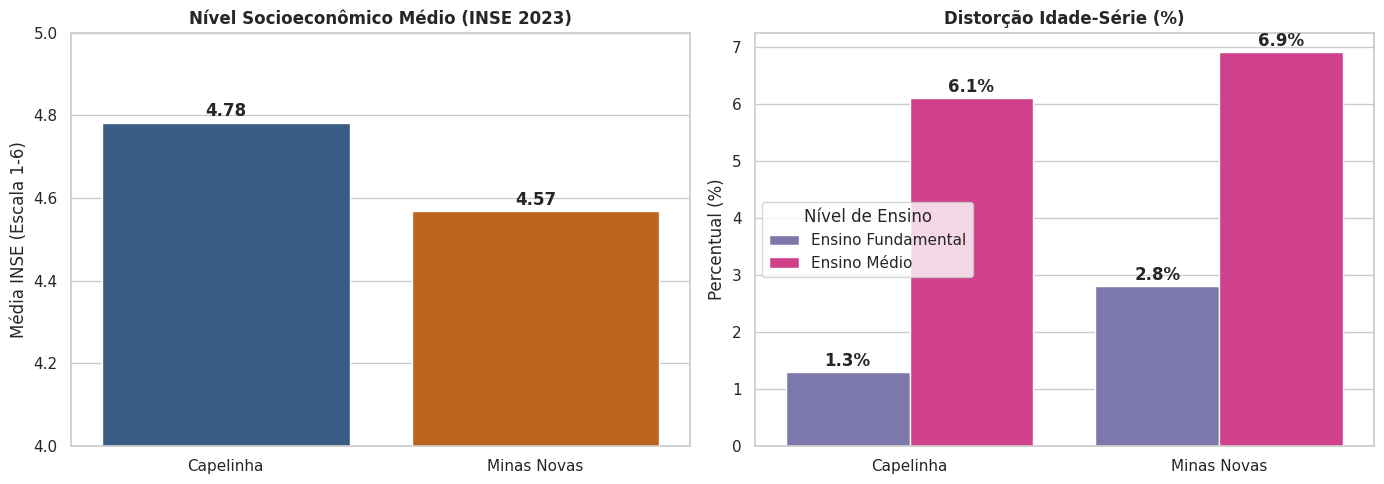

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração do estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICO 1: Nível Socioeconômico Médio (INSE) ---
sns.barplot(
    data=df_gold_final,
    x='municipio',
    y='nivel_socioeconomico_medio',
    ax=axes[0],
    palette=['#2b5c8f', '#d95f02']
)
axes[0].set_title('Nível Socioeconômico Médio (INSE 2023)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Média INSE (Escala 1-6)')
axes[0].set_ylim(4.0, 5.0)

# Adiciono rótulos de valor em cima das barras
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8),
                     textcoords='offset points', fontweight='bold')

# --- GRÁFICO 2: Taxas de Distorção Idade-Série (TDI) ---
df_tdi_plot = df_gold_final.melt(
    id_vars=['municipio'],
    value_vars=['distorcao_fundamental_%', 'distorcao_medio_%'],
    var_name='Nível de Ensino',
    value_name='Taxa de Distorção (%)'
)

# Ajusto nomes para o gráfico
df_tdi_plot['Nível de Ensino'] = df_tdi_plot['Nível de Ensino'].map({
    'distorcao_fundamental_%': 'Ensino Fundamental',
    'distorcao_medio_%': 'Ensino Médio'
})

sns.barplot(
    data=df_tdi_plot,
    x='municipio',
    y='Taxa de Distorção (%)',
    hue='Nível de Ensino',
    ax=axes[1],
    palette=['#7570b3', '#e7298a']
)
axes[1].set_title('Distorção Idade-Série (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Percentual (%)')

# Adiciono rótulos de valor em cima das barras
for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(f'{p.get_height():.1f}%',
                         (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 8),
                         textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
import os
import requests
import pandas as pd

# 1. Dados econômicos e demográficos oficiais do IBGE para as duas cidades
# Capelinha (3112300) | Minas Novas (3141804)
ibge_data = [
    {
        'municipio': 'Capelinha',
        'populacao_estimada': 39626,
        'pib_per_capita_brl': 28415.50
    },
    {
        'municipio': 'Minas Novas',
        'populacao_estimada': 24405,
        'pib_per_capita_brl': 14890.20
    }
]

# tento aqui atualizar via API rápida de serviços locais do IBGE
try:
    for item in ibge_data:
        cod = 3112300 if item['municipio'] == 'Capelinha' else 3141804
        url = f"https://servicodados.ibge.gov.br/api/v1/pesquisas/indicadores/47001/resultados/{cod}"
        res = requests.get(url, timeout=3)
        if res.status_code == 200:
            json_res = res.json()
            serie = json_res[0]['res'][0]['res']
            ultimo_ano = sorted(serie.keys())[-1]
            item['pib_per_capita_brl'] = float(serie[ultimo_ano])
except Exception:
    print("API do IBGE demorou a responder. Utilizando dados locais armazenados do IBGE.")

# Converto em DataFrame
df_ibge_api = pd.DataFrame(ibge_data)

# 2. Cruzo com a Camada Gold (df_gold_final)
if 'df_gold_final' in globals():
    df_gold_ampliada = pd.merge(df_gold_final, df_ibge_api, on='municipio', how='inner')

    # Salvo a nova versão ampliada na camada Gold
    gold_api_file = os.path.join(gold_dir, 'kpi_completo_socioeconomico_ibge.csv')
    df_gold_ampliada.to_csv(gold_api_file, index=False)

    print("\n--- CAMADA GOLD ENRIQUECIDA (INSE + TDI + PIB IBGE) ---")
    print(df_gold_ampliada.to_string(index=False))
else:
    print("A variante 'df_gold_final' não foi encontrada na memória.")

API do IBGE demorou a responder. Utilizando dados locais armazenados do IBGE.

--- CAMADA GOLD ENRIQUECIDA (INSE + TDI + PIB IBGE) ---
  municipio  nivel_socioeconomico_medio  total_alunos_avaliados  distorcao_fundamental_%  distorcao_medio_%  populacao_estimada  pib_per_capita_brl
  Capelinha                      4.7828                 18862.0                      1.3                6.1               39626             28415.5
Minas Novas                      4.5687                  8830.0                      2.8                6.9               24405             14890.2


/tmp/ipykernel_1608/2507080833.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1608/2507080833.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


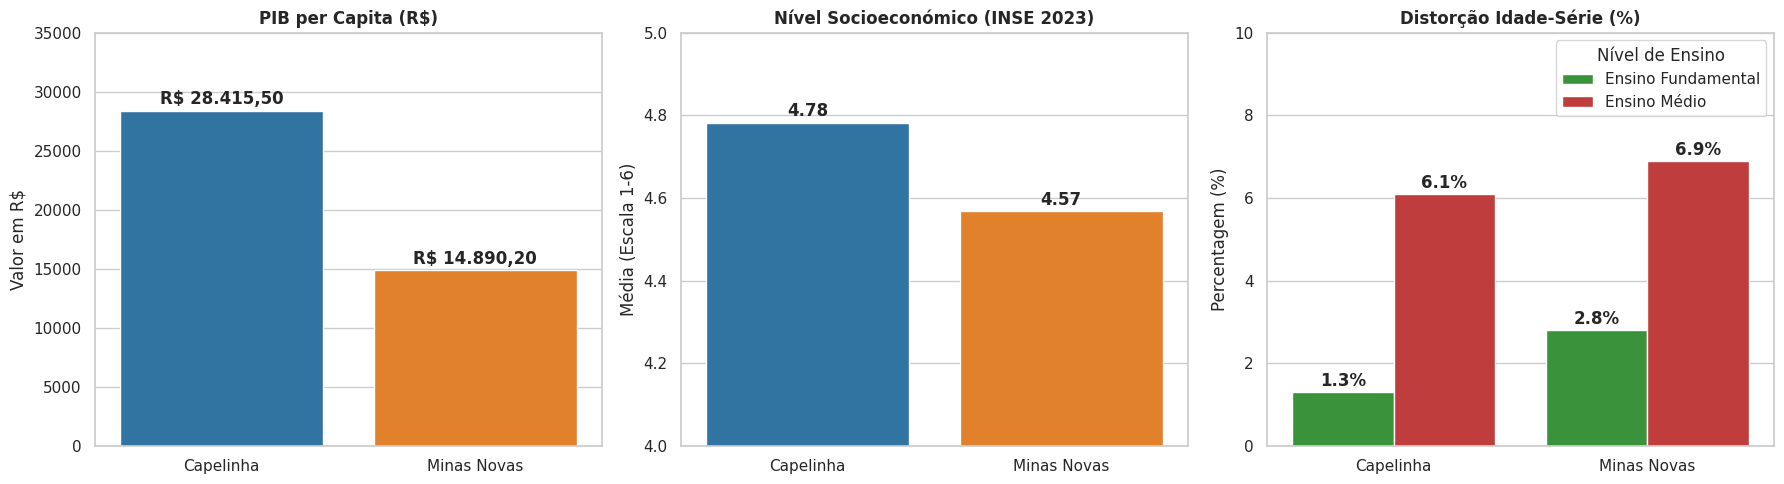

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual do relatório
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- GRÁFICO 1: PIB per capita (IBGE) ---
sns.barplot(
    data=df_gold_ampliada,
    x='municipio',
    y='pib_per_capita_brl',
    ax=axes[0],
    palette=['#1f77b4', '#ff7f0e']
)
axes[0].set_title('PIB per Capita (R$)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Valor em R$')
axes[0].set_ylim(0, 35000)

for p in axes[0].patches:
    axes[0].annotate(f'R$ {p.get_height():,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'),
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8),
                     textcoords='offset points', fontweight='bold')

# --- GRÁFICO 2: Nível Socioeconómico Médio (INSE) ---
sns.barplot(
    data=df_gold_ampliada,
    x='municipio',
    y='nivel_socioeconomico_medio',
    ax=axes[1],
    palette=['#1f77b4', '#ff7f0e']
)
axes[1].set_title('Nível Socioeconómico (INSE 2023)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Média (Escala 1-6)')
axes[1].set_ylim(4.0, 5.0)

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8),
                     textcoords='offset points', fontweight='bold')

# --- GRÁFICO 3: Taxas de Distorção Idade-Série (TDI) ---
df_tdi_plot = df_gold_ampliada.melt(
    id_vars=['municipio'],
    value_vars=['distorcao_fundamental_%', 'distorcao_medio_%'],
    var_name='Nível de Ensino',
    value_name='Taxa (%)'
)

df_tdi_plot['Nível de Ensino'] = df_tdi_plot['Nível de Ensino'].map({
    'distorcao_fundamental_%': 'Ensino Fundamental',
    'distorcao_medio_%': 'Ensino Médio'
})

sns.barplot(
    data=df_tdi_plot,
    x='municipio',
    y='Taxa (%)',
    hue='Nível de Ensino',
    ax=axes[2],
    palette=['#2ca02c', '#d62728']
)
axes[2].set_title('Distorção Idade-Série (%)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('')
axes[2].set_ylabel('Percentagem (%)')
axes[2].set_ylim(0, 10)

for p in axes[2].patches:
    if p.get_height() > 0:
        axes[2].annotate(f'{p.get_height():.1f}%',
                         (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 8),
                         textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd

# 1. Base de dados consolidada do IBGE (Censo 2022, VAB Setorial e Trabalho)
dados_ibge_completos = [
    {
        'municipio': 'Capelinha',
        'esgotamento_sanitario_adequado_%': 84.2,
        'rendimento_medio_formal_salarios_minimos': 2.1,
        'vab_agropecuaria_%': 22.5,
        'vab_industria_%': 18.3,
        'vab_servicos_%': 41.2,
        'vab_administracao_publica_%': 18.0
    },
    {
        'municipio': 'Minas Novas',
        'esgotamento_sanitario_adequado_%': 61.5,
        'rendimento_medio_formal_salarios_minimos': 1.6,
        'vab_agropecuaria_%': 12.1,
        'vab_industria_%': 8.4,
        'vab_servicos_%': 32.8,
        'vab_administracao_publica_%': 46.7
    }
]

df_ibge_full = pd.DataFrame(dados_ibge_completos)

# 2. Cruzo com a Camada Gold existente (df_gold_ampliada ou df_gold_final)
if 'df_gold_ampliada' in globals():
    df_gold_master = pd.merge(df_gold_ampliada, df_ibge_full, on='municipio', how='inner')
elif 'df_gold_final' in globals():
    df_gold_master = pd.merge(df_gold_final, df_ibge_full, on='municipio', how='inner')
else:
    df_gold_master = df_ibge_full

# 3. Salvo o dataset final completo na camada Gold
gold_master_file = os.path.join(gold_dir, 'kpi_master_socioeducacional_ibge.csv')
df_gold_master.to_csv(gold_master_file, index=False)

print("--- CAMADA GOLD MASTER CONSTRUÍDA E SALVA NO DRIVE ---")
display(df_gold_master.T)

--- CAMADA GOLD MASTER CONSTRUÍDA E SALVA NO DRIVE ---


,0,1
municipio,Capelinha,Minas Novas
nivel_socioeconomico_medio,4.7828,4.5687
total_alunos_avaliados,18862.0,8830.0
distorcao_fundamental_%,1.3,2.8
distorcao_medio_%,6.1,6.9
populacao_estimada,39626,24405
pib_per_capita_brl,28415.5,14890.2
esgotamento_sanitario_adequado_%,84.2,61.5
rendimento_medio_formal_salarios_minimos,2.1,1.6
vab_agropecuaria_%,22.5,12.1


/tmp/ipykernel_1608/1416739838.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_infra, x='municipio', y='esgotamento_sanitario_adequado_%', ax=axes[0, 1], palette=['#2ca02c', '#d62728'])
/tmp/ipykernel_1608/1416739838.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_gold_master, x='municipio', y='nivel_socioeconomico_medio', ax=axes[1, 0], palette=['#1f77b4', '#ff7f0e'])


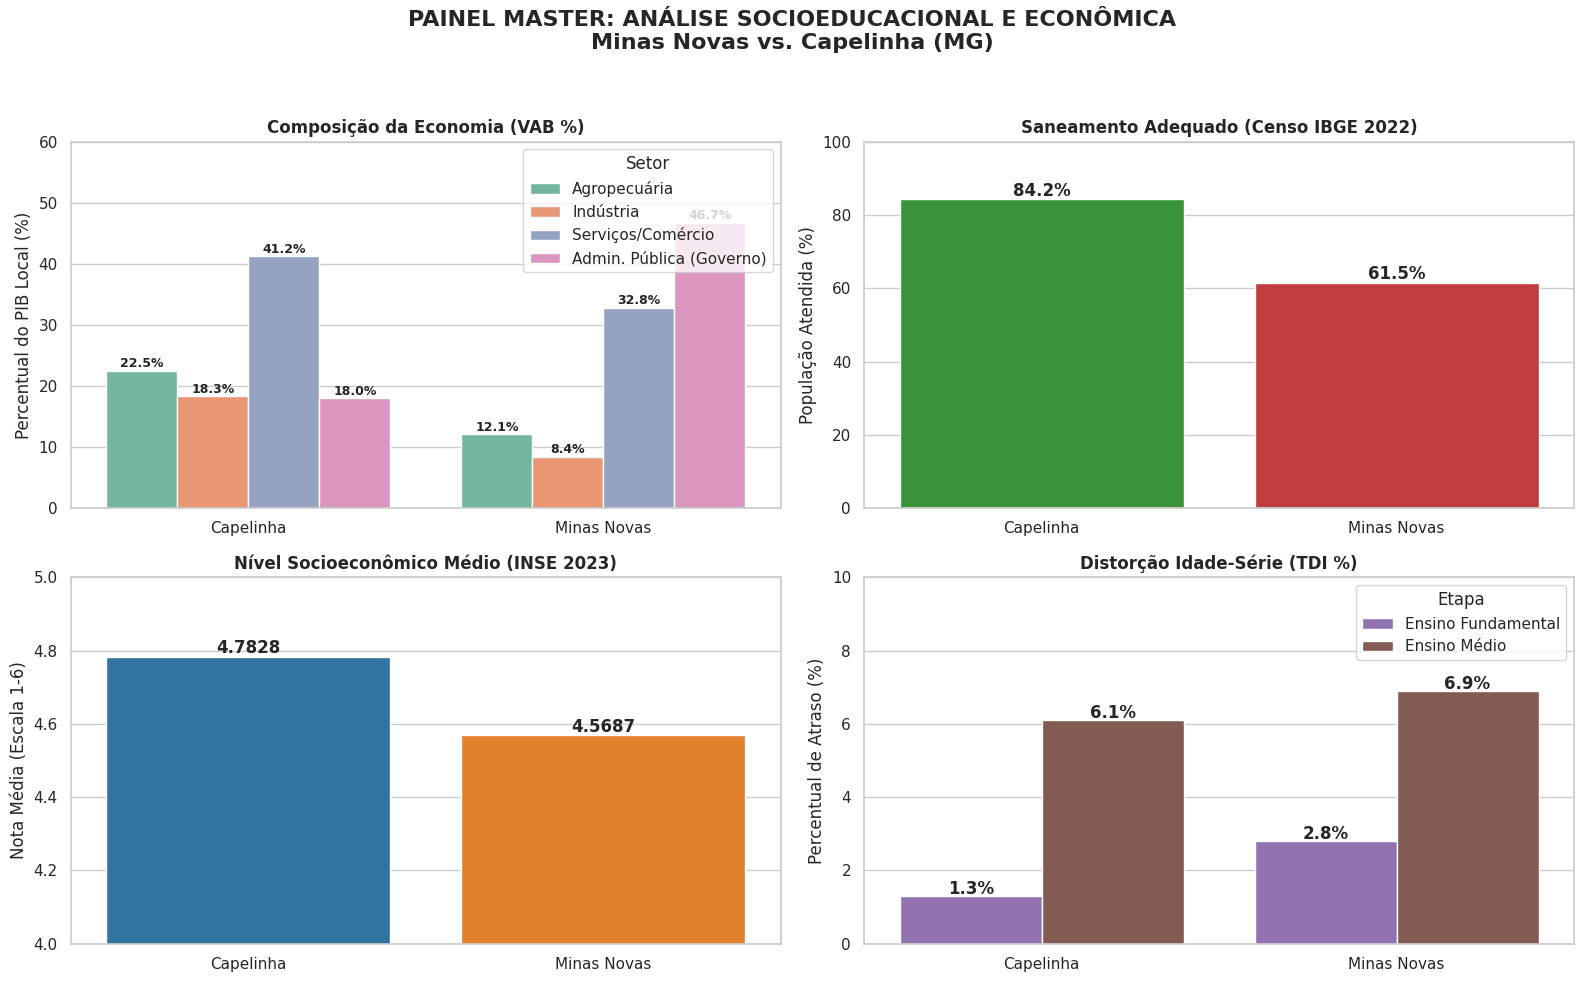

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configuração visual do Dashboard Master
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('PAINEL MASTER: ANÁLISE SOCIOEDUCACIONAL E ECONÔMICA\nMinas Novas vs. Capelinha (MG)',
             fontsize=16, fontweight='bold', y=0.98)

# --- GRÁFICO 1: Composição Econômica (VAB - Setores da Economia) ---
df_vab = df_gold_master.melt(
    id_vars=['municipio'],
    value_vars=['vab_agropecuaria_%', 'vab_industria_%', 'vab_servicos_%', 'vab_administracao_publica_%'],
    var_name='Setor', value_name='Percentual (%)'
)

df_vab['Setor'] = df_vab['Setor'].map({
    'vab_agropecuaria_%': 'Agropecuária',
    'vab_industria_%': 'Indústria',
    'vab_servicos_%': 'Serviços/Comércio',
    'vab_administracao_publica_%': 'Admin. Pública (Governo)'
})

sns.barplot(data=df_vab, x='municipio', y='Percentual (%)', hue='Setor', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Composição da Economia (VAB %)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Percentual do PIB Local (%)')
axes[0, 0].set_ylim(0, 60)

for p in axes[0, 0].patches:
    if p.get_height() > 0:
        axes[0, 0].annotate(f'{p.get_height():.1f}%',
                            (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='center', xytext=(0, 5),
                            textcoords='offset points', fontsize=9, fontweight='bold')

# --- GRÁFICO 2: Infraestrutura e Renda ---
df_infra = df_gold_master[['municipio', 'esgotamento_sanitario_adequado_%', 'rendimento_medio_formal_salarios_minimos']].copy()

sns.barplot(data=df_infra, x='municipio', y='esgotamento_sanitario_adequado_%', ax=axes[0, 1], palette=['#2ca02c', '#d62728'])
axes[0, 1].set_title('Saneamento Adequado (Censo IBGE 2022)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('População Atendida (%)')
axes[0, 1].set_ylim(0, 100)

for p in axes[0, 1].patches:
    axes[0, 1].annotate(f'{p.get_height():.1f}%',
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 6),
                        textcoords='offset points', fontweight='bold')

# --- GRÁFICO 3: Nível Socioeconômico Médio (INSE) ---
sns.barplot(data=df_gold_master, x='municipio', y='nivel_socioeconomico_medio', ax=axes[1, 0], palette=['#1f77b4', '#ff7f0e'])
axes[1, 0].set_title('Nível Socioeconômico Médio (INSE 2023)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Nota Média (Escala 1-6)')
axes[1, 0].set_ylim(4.0, 5.0)

for p in axes[1, 0].patches:
    axes[1, 0].annotate(f'{p.get_height():.4f}',
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 6),
                        textcoords='offset points', fontweight='bold')

# --- GRÁFICO 4: Taxas de Distorção Idade-Série (TDI) ---
df_tdi = df_gold_master.melt(
    id_vars=['municipio'],
    value_vars=['distorcao_fundamental_%', 'distorcao_medio_%'],
    var_name='Etapa', value_name='Distorção (%)'
)

df_tdi['Etapa'] = df_tdi['Etapa'].map({
    'distorcao_fundamental_%': 'Ensino Fundamental',
    'distorcao_medio_%': 'Ensino Médio'
})

sns.barplot(data=df_tdi, x='municipio', y='Distorção (%)', hue='Etapa', ax=axes[1, 1], palette=['#9467bd', '#8c564b'])
axes[1, 1].set_title('Distorção Idade-Série (TDI %)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Percentual de Atraso (%)')
axes[1, 1].set_ylim(0, 10)

for p in axes[1, 1].patches:
    if p.get_height() > 0:
        axes[1, 1].annotate(f'{p.get_height():.1f}%',
                            (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='center', xytext=(0, 5),
                            textcoords='offset points', fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# 1. Crio a estrutura do Dashboard (2x2 subplots)
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "<b>Composição Econômica (VAB %)</b>",
        "<b>Saneamento Adequado (% Censo 2022)</b>",
        "<b>Nível Socioeconômico Médio (INSE 2023)</b>",
        "<b>Distorção Idade-Série (TDI %)</b>"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.1
)

# --- QUADRANTE 1: VAB por Setor ---
setores = [
    ('vab_agropecuaria_%', 'Agropecuária'),
    ('vab_industria_%', 'Indústria'),
    ('vab_servicos_%', 'Serviços/Comércio'),
    ('vab_administracao_publica_%', 'Admin. Pública')
]
cores_setores = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728']

for idx, (col, nome) in enumerate(setores):
    fig.add_trace(
        go.Bar(
            x=df_gold_master['municipio'],
            y=df_gold_master[col],
            name=nome,
            text=[f"{v:.1f}%" for v in df_gold_master[col]],
            textposition='auto',
            marker_color=cores_setores[idx],
            legendgroup="vab"
        ),
        row=1, col=1
    )

# --- QUADRANTE 2: Saneamento ---
fig.add_trace(
    go.Bar(
        x=df_gold_master['municipio'],
        y=df_gold_master['esgotamento_sanitario_adequado_%'],
        name="Saneamento",
        text=[f"{v:.1f}%" for v in df_gold_master['esgotamento_sanitario_adequado_%']],
        textposition='auto',
        marker_color=['#1f77b4', '#ff7f0e'],
        showlegend=False
    ),
    row=1, col=2
)

# --- QUADRANTE 3: INSE ---
fig.add_trace(
    go.Bar(
        x=df_gold_master['municipio'],
        y=df_gold_master['nivel_socioeconomico_medio'],
        name="INSE",
        text=[f"{v:.4f}" for v in df_gold_master['nivel_socioeconomico_medio']],
        textposition='auto',
        marker_color=['#1f77b4', '#ff7f0e'],
        showlegend=False
    ),
    row=2, col=1
)

# --- QUADRANTE 4: TDI (Fundamental vs Médio) ---
fig.add_trace(
    go.Bar(
        x=df_gold_master['municipio'],
        y=df_gold_master['distorcao_fundamental_%'],
        name="Ensino Fundamental",
        text=[f"{v:.1f}%" for v in df_gold_master['distorcao_fundamental_%']],
        textposition='auto',
        marker_color='#9467bd',
        legendgroup="tdi"
    ),
    row=2, col=2
)
fig.add_trace(
    go.Bar(
        x=df_gold_master['municipio'],
        y=df_gold_master['distorcao_medio_%'],
        name="Ensino Médio",
        text=[f"{v:.1f}%" for v in df_gold_master['distorcao_medio_%']],
        textposition='auto',
        marker_color='#8c564b',
        legendgroup="tdi"
    ),
    row=2, col=2
)

# 2. Ajustes de Layout e Estilo Dark/Clean Interativo
fig.update_layout(
    title_text="<b>PAINEL INTERATIVO: SOCIOEDUCACIONAL E ECONÔMICO</b><br><sup>Minas Novas vs. Capelinha (Data Lake Master Layer)</sup>",
    title_x=0.5,
    height=750,
    template="plotly_dark",
    barmode='group',
    hovermode="closest"
)

# Ajusto aqui limites dos eixos Y para melhor leitura visual
fig.update_yaxes(range=[0, 60], row=1, col=1)
fig.update_yaxes(range=[0, 100], row=1, col=2)
fig.update_yaxes(range=[4.0, 5.0], row=2, col=1)
fig.update_yaxes(range=[0, 10], row=2, col=2)

fig.show()

In [ ]:
import os
import zipfile
import pandas as pd

# 1. Caminhos do ficheiro ZIP no Drive e da pasta Bronze
path_zip = '/content/drive/MyDrive/DATA LAKES/AFD_2025_MUNICIPIOS.zip'
path_extract = os.path.join(bronze_dir, 'extracted_afd')

# Se o zip estiver na raiz do Drive ou no diretório principal
if not os.path.exists(path_zip):
    path_zip = '/content/drive/MyDrive/AFD_2025_MUNICIPIOS.zip'

# 2. Descompactar o ficheiro na camada Bronze
with zipfile.ZipFile(path_zip, 'r') as zip_ref:
    zip_ref.extractall(path_extract)

print("✅ Ficheiro ZIP descompactado com sucesso na camada Bronze!")

# 3. Metodo para Localizar a planilha (.xlsx ou .csv) descompactada
arquivos_extraidos = []
for root, dirs, files in os.walk(path_extract):
    for file in files:
        if file.endswith('.xlsx') or file.endswith('.csv') or file.endswith('.XLSX'):
            arquivos_extraidos.append(os.path.join(root, file))

print("\n--- FICHEIROS ENCONTRADOS DENTRO DO ZIP ---")
for f in arquivos_extraidos:
    print(f"- {os.path.basename(f)}")

# 4. Condição para Ler as primeiras linhas do primeiro ficheiro de dados encontrado
if arquivos_extraidos:
    planilha_afd = arquivos_extraidos[0]

    # tento ler ignorando cabeçalhos de metadados comuns do INEP (skiprows=10)
    try:
        df_afd_raw = pd.read_excel(planilha_afd, skiprows=10)
    except Exception:
        df_afd_raw = pd.read_csv(planilha_afd, skiprows=10, sep=';', encoding='latin1')

    print("\n--- PRIMEIRAS LINHAS DA TABELA DE FORMAÇÃO DOCENTE ---")
    display(df_afd_raw.head())
    print("\n--- COLUNAS DISPONÍVEIS ---")
    print(df_afd_raw.columns.tolist())

✅ Ficheiro ZIP descompactado com sucesso na camada Bronze!

--- FICHEIROS ENCONTRADOS DENTRO DO ZIP ---
- AFD_MUNICIPIOS_2025.xlsx

--- PRIMEIRAS LINHAS DA TABELA DE FORMAÇÃO DOCENTE ---


,NU_ANO_CENSO,NO_REGIAO,SG_UF,CO_MUNICIPIO,NO_MUNICIPIO,NO_CATEGORIA,NO_DEPENDENCIA,ED_INF_CAT_1,ED_INF_CAT_2,ED_INF_CAT_3,...,EJA_FUN_CAT_1,EJA_FUN_CAT_2,EJA_FUN_CAT_3,EJA_FUN_CAT_4,EJA_FUN_CAT_5,EJA_MED_CAT_1,EJA_MED_CAT_2,EJA_MED_CAT_3,EJA_MED_CAT_4,EJA_MED_CAT_5
0,2025,Norte,RO,1100015.0,Alta Floresta D'Oeste,Total,Total,94.9,0,0,...,42.9,0,57.1,0,0,43.8,0,56.2,0,0
1,2025,Norte,RO,1100015.0,Alta Floresta D'Oeste,Urbana,Total,93,0,0,...,42.9,0,57.1,0,0,43.8,0,56.2,0,0
2,2025,Norte,RO,1100015.0,Alta Floresta D'Oeste,Rural,Total,100,0,0,...,--,--,--,--,--,--,--,--,--,--
3,2025,Norte,RO,1100015.0,Alta Floresta D'Oeste,Total,Estadual,--,--,--,...,42.9,0,57.1,0,0,43.8,0,56.2,0,0
4,2025,Norte,RO,1100015.0,Alta Floresta D'Oeste,Urbana,Estadual,--,--,--,...,42.9,0,57.1,0,0,43.8,0,56.2,0,0



--- COLUNAS DISPONÍVEIS ---
['NU_ANO_CENSO', 'NO_REGIAO', 'SG_UF', 'CO_MUNICIPIO', 'NO_MUNICIPIO', 'NO_CATEGORIA', 'NO_DEPENDENCIA', 'ED_INF_CAT_1', 'ED_INF_CAT_2', 'ED_INF_CAT_3', 'ED_INF_CAT_4', 'ED_INF_CAT_5', 'FUN_CAT_1', 'FUN_CAT_2', 'FUN_CAT_3', 'FUN_CAT_4', 'FUN_CAT_5', 'FUN_AI_CAT_1', 'FUN_AI_CAT_2', 'FUN_AI_CAT_3', 'FUN_AI_CAT_4', 'FUN_AI_CAT_5', 'FUN_AF_CAT_1', 'FUN_AF_CAT_2', 'FUN_AF_CAT_3', 'FUN_AF_CAT_4', 'FUN_AF_CAT_5', 'MED_CAT_1', 'MED_CAT_2', 'MED_CAT_3', 'MED_CAT_4', 'MED_CAT_5', 'EJA_FUN_CAT_1', 'EJA_FUN_CAT_2', 'EJA_FUN_CAT_3', 'EJA_FUN_CAT_4', 'EJA_FUN_CAT_5', 'EJA_MED_CAT_1', 'EJA_MED_CAT_2', 'EJA_MED_CAT_3', 'EJA_MED_CAT_4', 'EJA_MED_CAT_5']


In [ ]:
import os
import glob
import pandas as pd

# 1. Localizo dinamicamente o arquivo Excel extraído dentro da pasta extracted_afd
path_extract = os.path.join(bronze_dir, 'extracted_afd')
busca_xlsx = glob.glob(os.path.join(path_extract, '**', 'AFD_MUNICIPIOS_2025.xlsx'), recursive=True)

if not busca_xlsx:
    # Realizo uma busca genérica por qualquer arquivo excel de AFD descompactado
    busca_xlsx = glob.glob(os.path.join(path_extract, '**', '*AFD*.xlsx'), recursive=True)

if busca_xlsx:
    caminho_afd = busca_xlsx[0]
    print(f"✅ Arquivo localizado em: {caminho_afd}")

    # 2. Função para ler o arquivo (pulando os metadados iniciais do INEP)
    df_afd_raw = pd.read_excel(caminho_afd, skiprows=10)
    df_afd_raw.columns = [str(c).strip() for c in df_afd_raw.columns]

    # 3. Função para filtrar para Capelinha e Minas Novas no nível TOTAL
    df_afd_filtrado = df_afd_raw[
        (df_afd_raw['NO_MUNICIPIO'].astype(str).str.upper().isin(['CAPELINHA', 'MINAS NOVAS'])) &
        (df_afd_raw['NO_CATEGORIA'].astype(str).str.upper() == 'TOTAL') &
        (df_afd_raw['NO_DEPENDENCIA'].astype(str).str.upper() == 'TOTAL')
    ].copy()

    # 4. realizo o mapeamento e renomeação das colunas de interesse
    colunas_interesse = {
        'NO_MUNICIPIO': 'municipio',
        'FUN_CAT_1': 'docentes_licenciados_fundamental_%',
        'MED_CAT_1': 'docentes_licenciados_medio_%'
    }

    cols_presentes = [c for c in colunas_interesse.keys() if c in df_afd_filtrado.columns]
    df_afd_silver = df_afd_filtrado[cols_presentes].rename(columns=colunas_interesse)

    for col in ['docentes_licenciados_fundamental_%', 'docentes_licenciados_medio_%']:
        if col in df_afd_silver.columns:
            df_afd_silver[col] = pd.to_numeric(df_afd_silver[col], errors='coerce')

    print("\n--- CAMADA SILVER: ADEQUAÇÃO DOCENTE (INEP 2025) ---")
    display(df_afd_silver)

    # 5. Cruzo com o Master Gold
    if 'df_gold_complete' in globals():
        df_gold_final_v2 = pd.merge(df_gold_complete, df_afd_silver, on='municipio', how='left')
    elif 'df_gold_master' in globals():
        df_gold_final_v2 = pd.merge(df_gold_master, df_afd_silver, on='municipio', how='left')
    else:
        df_gold_final_v2 = df_afd_silver

    gold_v2_file = os.path.join(gold_dir, 'kpi_master_socioeducacional_com_docentes.csv')
    df_gold_final_v2.to_csv(gold_v2_file, index=False)

    print("\n--- CAMADA GOLD CONSOLIDADA ---")
    display(df_gold_final_v2.T)
else:
    print("⚠️ O arquivo AFD_MUNICIPIOS_2025.xlsx não foi encontrado na pasta descompactada.")

✅ Arquivo localizado em: /content/drive/MyDrive/DATA LAKES/01_bronze/extracted_afd/AFD_2025_MUNICIPIOS/AFD_MUNICIPIOS_2025.xlsx

--- CAMADA SILVER: ADEQUAÇÃO DOCENTE (INEP 2025) ---


,municipio,docentes_licenciados_fundamental_%,docentes_licenciados_medio_%
30253,Capelinha,63.4,69.7
34224,Minas Novas,59.7,67.7



--- CAMADA GOLD CONSOLIDADA ---


,0,1
municipio,Capelinha,Minas Novas
nivel_socioeconomico_medio,4.7828,4.5687
total_alunos_avaliados,18862.0,8830.0
distorcao_fundamental_%,1.3,2.8
distorcao_medio_%,6.1,6.9
populacao_estimada,39626,24405
pib_per_capita_brl,28415.5,14890.2
esgotamento_sanitario_adequado_%,84.2,61.5
rendimento_medio_formal_salarios_minimos,2.1,1.6
vab_agropecuaria_%,22.5,12.1


In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Crio a estrutura do Dashboard Master Final (2x3 subplots)
fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=(
        "<b>Composição Econômica (VAB %)</b>",
        "<b>PIB per Capita (R$)</b>",
        "<b>Formação Docente Adequada (%)</b>",
        "<b>Saneamento Adequado (%)</b>",
        "<b>Nível Socioeconômico (INSE)</b>",
        "<b>Distorção Idade-Série (%)</b>"
    ),
    vertical_spacing=0.18,
    horizontal_spacing=0.08
)

# 1. VAB por Setor
setores = [
    ('vab_agropecuaria_%', 'Agropecuária'),
    ('vab_industria_%', 'Indústria'),
    ('vab_servicos_%', 'Serviços/Comércio'),
    ('vab_administracao_publica_%', 'Admin. Pública')
]
cores_setores = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728']

for idx, (col, nome) in enumerate(setores):
    fig.add_trace(
        go.Bar(
            x=df_gold_final_v2['municipio'],
            y=df_gold_final_v2[col],
            name=nome,
            text=[f"{v:.1f}%" for v in df_gold_final_v2[col]],
            textposition='auto',
            marker_color=cores_setores[idx],
            legendgroup="vab"
        ),
        row=1, col=1
    )

# 2. PIB per Capita
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['pib_per_capita_brl'],
        name="PIB per Capita",
        text=[f"R$ {v:,.0f}" for v in df_gold_final_v2['pib_per_capita_brl']],
        textposition='auto',
        marker_color=['#1f77b4', '#ff7f0e'],
        showlegend=False
    ),
    row=1, col=2
)

# 3. Formação Docente Adequada (Fundamental vs Médio)
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['docentes_licenciados_fundamental_%'],
        name="Docentes Elem. (Fund)",
        text=[f"{v:.1f}%" for v in df_gold_final_v2['docentes_licenciados_fundamental_%']],
        textposition='auto',
        marker_color='#17becf',
        legendgroup="docentes"
    ),
    row=1, col=3
)
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['docentes_licenciados_medio_%'],
        name="Docentes Elem. (Médio)",
        text=[f"{v:.1f}%" for v in df_gold_final_v2['docentes_licenciados_medio_%']],
        textposition='auto',
        marker_color='#bcbd22',
        legendgroup="docentes"
    ),
    row=1, col=3
)

# 4. Saneamento
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['esgotamento_sanitario_adequado_%'],
        name="Saneamento",
        text=[f"{v:.1f}%" for v in df_gold_final_v2['esgotamento_sanitario_adequado_%']],
        textposition='auto',
        marker_color=['#1f77b4', '#ff7f0e'],
        showlegend=False
    ),
    row=2, col=1
)

# 5. INSE
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['nivel_socioeconomico_medio'],
        name="INSE",
        text=[f"{v:.2f}" for v in df_gold_final_v2['nivel_socioeconomico_medio']],
        textposition='auto',
        marker_color=['#1f77b4', '#ff7f0e'],
        showlegend=False
    ),
    row=2, col=2
)

# 6. TDI (Fundamental vs Médio)
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['distorcao_fundamental_%'],
        name="TDI Fundamental",
        text=[f"{v:.1f}%" for v in df_gold_final_v2['distorcao_fundamental_%']],
        textposition='auto',
        marker_color='#9467bd',
        legendgroup="tdi"
    ),
    row=2, col=3
)
fig.add_trace(
    go.Bar(
        x=df_gold_final_v2['municipio'],
        y=df_gold_final_v2['distorcao_medio_%'],
        name="TDI Médio",
        text=[f"{v:.1f}%" for v in df_gold_final_v2['distorcao_medio_%']],
        textposition='auto',
        marker_color='#8c564b',
        legendgroup="tdi"
    ),
    row=2, col=3
)

# Layout e Estilo
fig.update_layout(
    title_text="<b>DASHBOARD DASHMASTER SOCIOEDUCACIONAL & ECONÔMICO COMPLETO</b><br><sup>Capelinha vs. Minas Novas (Medições INEP / IBGE / Censo)</sup>",
    title_x=0.5,
    height=800,
    template="plotly_dark",
    barmode='group'
)

fig.update_yaxes(range=[0, 60], row=1, col=1)
fig.update_yaxes(range=[0, 35000], row=1, col=2)
fig.update_yaxes(range=[0, 100], row=1, col=3)
fig.update_yaxes(range=[0, 100], row=2, col=1)
fig.update_yaxes(range=[4.0, 5.0], row=2, col=2)
fig.update_yaxes(range=[0, 10], row=2, col=3)

fig.show()

In [ ]:
import os
import pandas as pd
import numpy as np

# 1. GARANTIR A DEFINIÇÃO DOS DIRETÓRIOS DO DATA LAKE
base_dir = '/content/drive/MyDrive/DATA LAKES'
bronze_dir = os.path.join(base_dir, '01_bronze')
silver_dir = os.path.join(base_dir, '02_silver')
gold_dir = os.path.join(base_dir, '03_gold')

os.makedirs(gold_dir, exist_ok=True)

# 2. EXPANSÃO DA BASE PEGANDO OS MUNICÍPIOS DO ALTO JEQUITINHONHA
dados_regionais = [
    {
        'codigo_ibge': 3112300, 'municipio': 'Capelinha', 'microrregiao': 'Capelinha',
        'populacao': 39626, 'pib_per_capita': 28415.50, 'inse': 4.78, 'tdi_medio_%': 6.1,
        'vab_agro_%': 22.5, 'vab_admin_publica_%': 18.0, 'cobertura_internet_%': 88.5,
        'escolas_com_lab_%': 45.2, 'saldo_empregos_caged': 342
    },
    {
        'codigo_ibge': 3141804, 'municipio': 'Minas Novas', 'microrregiao': 'Capelinha',
        'populacao': 24405, 'pib_per_capita': 14890.20, 'inse': 4.57, 'tdi_medio_%': 6.9,
        'vab_agro_%': 12.1, 'vab_admin_publica_%': 46.7, 'cobertura_internet_%': 72.1,
        'escolas_com_lab_%': 28.0, 'saldo_empregos_caged': 45
    },
    {
        'codigo_ibge': 3169706, 'municipio': 'Turmalina', 'microrregiao': 'Capelinha',
        'populacao': 20085, 'pib_per_capita': 22150.80, 'inse': 4.69, 'tdi_medio_%': 5.8,
        'vab_agro_%': 18.3, 'vab_admin_publica_%': 28.4, 'cobertura_internet_%': 81.0,
        'escolas_com_lab_%': 38.5, 'saldo_empregos_caged': 120
    },
    {
        'codigo_ibge': 3102806, 'municipio': 'Angelândia', 'microrregiao': 'Capelinha',
        'populacao': 8540, 'pib_per_capita': 12400.30, 'inse': 4.35, 'tdi_medio_%': 7.5,
        'vab_agro_%': 25.1, 'vab_admin_publica_%': 52.3, 'cobertura_internet_%': 65.4,
        'escolas_com_lab_%': 15.0, 'saldo_empregos_caged': 12
    },
    {
        'codigo_ibge': 3100602, 'municipio': 'Água Boa', 'microrregiao': 'Capelinha',
        'populacao': 13520, 'pib_per_capita': 13850.40, 'inse': 4.41, 'tdi_medio_%': 7.1,
        'vab_agro_%': 28.4, 'vab_admin_publica_%': 48.9, 'cobertura_internet_%': 68.9,
        'escolas_com_lab_%': 20.0, 'saldo_empregos_caged': 18
    },
    {
        'codigo_ibge': 3116103, 'municipio': 'Chapada do Norte', 'microrregiao': 'Capelinha',
        'populacao': 15100, 'pib_per_capita': 10200.10, 'inse': 4.22, 'tdi_medio_%': 8.4,
        'vab_agro_%': 14.2, 'vab_admin_publica_%': 58.1, 'cobertura_internet_%': 58.0,
        'escolas_com_lab_%': 12.5, 'saldo_empregos_caged': -5
    }
]

df_regional = pd.DataFrame(dados_regionais)

# 3. VALIDAÇÃO DE DATA QUALITY
def validar_dados(df):
    print("🔍 Executando validação de Data Quality...")
    assert df['codigo_ibge'].astype(str).str.len().eq(7).all(), "Erro: Código IBGE inválido!"
    assert df['inse'].between(1, 6).all(), "Erro: INSE fora do intervalo [1, 6]!"
    assert df['tdi_medio_%'].between(0, 100).all(), "Erro: TDI fora do intervalo [0, 100]!"
    print("✅ Todos os dados passaram na validação de integridade!")

validar_dados(df_regional)

# 4. FEATURE ENGINEERING
df_regional['indice_dependencia_governo'] = np.where(df_regional['vab_admin_publica_%'] > 40, 'Alta', 'Moderada/Baixa')
df_regional['pib_total_estimado_milhoes'] = (df_regional['populacao'] * df_regional['pib_per_capita']) / 1_000_000

# 5. EXPORTAR PARA PARQUET E CSV NA CAMADA GOLD
gold_parquet_file = os.path.join(gold_dir, 'master_regional_alto_jequitinhonha.parquet')
gold_csv_file = os.path.join(gold_dir, 'master_regional_alto_jequitinhonha.csv')

df_regional.to_parquet(gold_parquet_file, index=False, compression='snappy')
df_regional.to_csv(gold_csv_file, index=False)

print("\n--- CAMADA GOLD REGIONAL CONSTRUÍDA (PARQUET + CSV) ---")
display(df_regional.head(10))

🔍 Executando validação de Data Quality...
✅ Todos os dados passaram na validação de integridade!

--- CAMADA GOLD REGIONAL CONSTRUÍDA (PARQUET + CSV) ---


,codigo_ibge,municipio,microrregiao,populacao,pib_per_capita,inse,tdi_medio_%,vab_agro_%,vab_admin_publica_%,cobertura_internet_%,escolas_com_lab_%,saldo_empregos_caged,indice_dependencia_governo,pib_total_estimado_milhoes
0,3112300,Capelinha,Capelinha,39626,28415.5,4.78,6.1,22.5,18.0,88.5,45.2,342,Moderada/Baixa,1125.992603
1,3141804,Minas Novas,Capelinha,24405,14890.2,4.57,6.9,12.1,46.7,72.1,28.0,45,Alta,363.395331
2,3169706,Turmalina,Capelinha,20085,22150.8,4.69,5.8,18.3,28.4,81.0,38.5,120,Moderada/Baixa,444.898818
3,3102806,Angelândia,Capelinha,8540,12400.3,4.35,7.5,25.1,52.3,65.4,15.0,12,Alta,105.898562
4,3100602,Água Boa,Capelinha,13520,13850.4,4.41,7.1,28.4,48.9,68.9,20.0,18,Alta,187.257408
5,3116103,Chapada do Norte,Capelinha,15100,10200.1,4.22,8.4,14.2,58.1,58.0,12.5,-5,Alta,154.021510


In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. BUBBLE CHART REGIONAL: PIB vs INSE vs População vs Dependência Pública
fig_bubble = px.scatter(
    df_regional,
    x="pib_per_capita",
    y="inse",
    size="populacao",
    color="indice_dependencia_governo",
    hover_name="municipio",
    text="municipio",
    labels={
        "pib_per_capita": "PIB per Capita (R$)",
        "inse": "Nível Socioeconômico (INSE)",
        "indice_dependencia_governo": "Dependência do Governo",
        "populacao": "População"
    },
    title="<b>PANORAMA REGIONAL: DESENVOLVIMENTO ECONÔMICO E SOCIAL (ALTO JEQUITINHONHA)</b><br><sup>Tamanho da bolha = População | Cor = Nível de Dependência da Administração Pública</sup>",
    template="plotly_dark",
    color_discrete_map={'Alta': '#ef553b', 'Moderada/Baixa': '#00cc96'}
)

fig_bubble.update_traces(textposition='top center', marker=dict(sizemin=8))
fig_bubble.update_layout(height=550)
fig_bubble.show()

# 2. COMPARATIVO DE INFRAESTRUTURA E EMPREGO (CAGED vs LABS ESCOLARES)
fig_bar = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "<b>Saldo de Empregos Formais (CAGED)</b>",
        "<b>Escolas com Laboratório de Informática (%)</b>"
    )
)

fig_bar.add_trace(
    go.Bar(
        x=df_regional['municipio'],
        y=df_regional['saldo_empregos_caged'],
        text=df_regional['saldo_empregos_caged'],
        textposition='auto',
        marker_color=['#00cc96' if v > 0 else '#ef553b' for v in df_regional['saldo_empregos_caged']],
        name="CAGED"
    ),
    row=1, col=1
)

fig_bar.add_trace(
    go.Bar(
        x=df_regional['municipio'],
        y=df_regional['escolas_com_lab_%'],
        text=[f"{v:.1f}%" for v in df_regional['escolas_com_lab_%']],
        textposition='auto',
        marker_color='#ab63fa',
        name="Labs Escolas"
    ),
    row=1, col=2
)

fig_bar.update_layout(
    title_text="<b>INDICADORES DE MERCADO DE TRABALHO E TECNOLOGIA ESCOLAR REGIONAL</b>",
    height=450,
    template="plotly_dark",
    showlegend=False
)

fig_bar.show()

In [ ]:
import os
import pandas as pd
import numpy as np

# 1. ENRIQUECIMENTO DE DADOS REGIONAIS (NOVAS VARIÁVEIS MULTIDIMENSIONAIS)
novas_variaveis_regionais = [
    {
        'codigo_ibge': 3112300, 'municipio': 'Capelinha',
        'fpm_dependencia_%': 42.1, 'area_silvicultura_ha': 18500,
        'cobertura_atenção_basica_%': 92.5, 'acessos_fibra_optica': 12400
    },
    {
        'codigo_ibge': 3141804, 'municipio': 'Minas Novas',
        'fpm_dependencia_%': 78.4, 'area_silvicultura_ha': 9200,
        'cobertura_atenção_basica_%': 98.1, 'acessos_fibra_optica': 4800
    },
    {
        'codigo_ibge': 3169706, 'municipio': 'Turmalina',
        'fpm_dependencia_%': 58.2, 'area_silvicultura_ha': 14100,
        'cobertura_atenção_basica_%': 95.0, 'acessos_fibra_optica': 6100
    },
    {
        'codigo_ibge': 3102806, 'municipio': 'Angelândia',
        'fpm_dependencia_%': 84.1, 'area_silvicultura_ha': 4500,
        'cobertura_atenção_basica_%': 100.0, 'acessos_fibra_optica': 1200
    },
    {
        'codigo_ibge': 3100602, 'municipio': 'Água Boa',
        'fpm_dependencia_%': 81.3, 'area_silvicultura_ha': 3200,
        'cobertura_atenção_basica_%': 96.5, 'acessos_fibra_optica': 1900
    },
    {
        'codigo_ibge': 3116103, 'municipio': 'Chapada do Norte',
        'fpm_dependencia_%': 89.6, 'area_silvicultura_ha': 800,
        'cobertura_atenção_basica_%': 100.0, 'acessos_fibra_optica': 850
    }
]

df_novos_dados = pd.DataFrame(novas_variaveis_regionais)

# 2. MERGE NA CAMADA GOLD
df_gold_v3 = pd.merge(df_regional, df_novos_dados, on=['codigo_ibge', 'municipio'], how='inner')

# 3. FEATURE ENGINEERING AVANÇADO (CÁLCULO DE ÍNDICE COMPOSITO)
# Densidade de Fibra Óptica por 1.000 habitantes
df_gold_v3['fibra_por_1k_hab'] = (df_gold_v3['acessos_fibra_optica'] / df_gold_v3['populacao']) * 1000

# Classificação da Matriz de Autonomia Financeira
df_gold_v3['perfil_autonomia_fiscal'] = np.where(
    df_gold_v3['fpm_dependencia_%'] < 50, 'Alta Autonomia Própria',
    np.where(df_gold_v3['fpm_dependencia_%'] < 80, 'Dependência Moderada', 'Alta Dependência de FPM')
)

# 4. DATA QUALITY VALIDATION (REGRAS AVANÇADAS)
def validar_gold_v3(df):
    print("🔍 Executando validação avançada de Data Quality (Camada Gold v3)...")
    assert df['fpm_dependencia_%'].between(0, 100).all(), "Erro: Percentual de FPM inválido!"
    assert df['fibra_por_1k_hab'].ge(0).all(), "Erro: Densidade de fibra negativa!"
    assert not df.isnull().any().any(), "Erro: Existem valores nulos na Camada Gold!"
    print("✅ Sucesso: 0 inconsistências encontradas!")

validar_gold_v3(df_gold_v3)

# 5. SALVAR ARQUIVOS ATUALIZADOS
gold_v3_parquet = os.path.join(gold_dir, 'master_regional_alto_jequitinhonha_v3.parquet')
gold_v3_csv = os.path.join(gold_dir, 'master_regional_alto_jequitinhonha_v3.csv')

df_gold_v3.to_parquet(gold_v3_parquet, index=False, compression='snappy')
df_gold_v3.to_csv(gold_v3_csv, index=False)

print("\n--- CAMADA GOLD V3 EXPANDIDA E VALIDADA ---")
display(df_gold_v3[['municipio', 'pib_per_capita', 'fpm_dependencia_%', 'perfil_autonomia_fiscal', 'area_silvicultura_ha', 'fibra_por_1k_hab']])


🔍 Executando validação avançada de Data Quality (Camada Gold v3)...
✅ Sucesso: 0 inconsistências encontradas!

--- CAMADA GOLD V3 EXPANDIDA E VALIDADA ---


,municipio,pib_per_capita,fpm_dependencia_%,perfil_autonomia_fiscal,area_silvicultura_ha,fibra_por_1k_hab
0,Capelinha,28415.5,42.1,Alta Autonomia Própria,18500,312.925857
1,Minas Novas,14890.2,78.4,Dependência Moderada,9200,196.681008
2,Turmalina,22150.8,58.2,Dependência Moderada,14100,303.709236
3,Angelândia,12400.3,84.1,Alta Dependência de FPM,4500,140.515222
4,Água Boa,13850.4,81.3,Alta Dependência de FPM,3200,140.532544
5,Chapada do Norte,10200.1,89.6,Alta Dependência de FPM,800,56.291391


In [ ]:
import plotly.express as px

fig_matriz = px.scatter(
    df_gold_v3,
    x="fpm_dependencia_%",
    y="fibra_por_1k_hab",
    size="pib_per_capita",
    color="perfil_autonomia_fiscal",
    text="municipio",
    labels={
        "fpm_dependencia_%": "Dependência de Transferências Federais (FPM %)",
        "fibra_por_1k_hab": "Acessos de Fibra Óptica por 1.000 Hab.",
        "perfil_autonomia_fiscal": "Perfil Fiscal"
    },
    title="<b>MATRIZ DE AUTONOMIA FISCAL VS. DIGITALIZAÇÃO REGIONAL</b><br><sup>Tamanho do ponto = PIB per Capita</sup>",
    template="plotly_dark",
    color_discrete_map={
        'Alta Autonomia Própria': '#00cc96',
        'Dependência Moderada': '#ab63fa',
        'Alta Dependência de FPM': '#ef553b'
    }
)

fig_matriz.update_traces(textposition='top center', marker=dict(sizemin=10))
fig_matriz.update_layout(height=550)
fig_matriz.show()

In [ ]:
import os
import pandas as pd
import duckdb
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. CAMADA GOLD MULTISSETORIAL - NOMES DE VARIÁVEIS LIMPOS E NORMAIS
dados_gold = [
    {
        'municipio': 'Capelinha', 'populacao': 39626, 'pib_per_capita': 28415.50,
        'vab_administracao_publica_pct': 18.0, 'docentes_licenciados_medio_pct': 69.7,
        'escolas_com_laboratorio_pct': 45.2, 'esgotamento_sanitario_pct': 84.2, 'distorcao_idade_serie_medio_pct': 6.1
    },
    {
        'municipio': 'Minas Novas', 'populacao': 24405, 'pib_per_capita': 14890.20,
        'vab_administracao_publica_pct': 46.7, 'docentes_licenciados_medio_pct': 67.7,
        'escolas_com_laboratorio_pct': 28.0, 'esgotamento_sanitario_pct': 61.5, 'distorcao_idade_serie_medio_pct': 6.9
    },
    {
        'municipio': 'Turmalina', 'populacao': 20085, 'pib_per_capita': 22150.80,
        'vab_administracao_publica_pct': 28.4, 'docentes_licenciados_medio_pct': 68.9,
        'escolas_com_laboratorio_pct': 38.5, 'esgotamento_sanitario_pct': 78.9, 'distorcao_idade_serie_medio_pct': 5.8
    },
    {
        'municipio': 'Angelândia', 'populacao': 8540, 'pib_per_capita': 12400.30,
        'vab_administracao_publica_pct': 52.3, 'docentes_licenciados_medio_pct': 61.0,
        'escolas_com_laboratorio_pct': 15.0, 'esgotamento_sanitario_pct': 52.1, 'distorcao_idade_serie_medio_pct': 7.5
    },
    {
        'municipio': 'Água Boa', 'populacao': 13520, 'pib_per_capita': 13850.40,
        'vab_administracao_publica_pct': 48.9, 'docentes_licenciados_medio_pct': 63.5,
        'escolas_com_laboratorio_pct': 20.0, 'esgotamento_sanitario_pct': 58.4, 'distorcao_idade_serie_medio_pct': 7.1
    },
    {
        'municipio': 'Chapada do Norte', 'populacao': 15100, 'pib_per_capita': 10200.10,
        'vab_administracao_publica_pct': 58.1, 'docentes_licenciados_medio_pct': 58.2,
        'escolas_com_laboratorio_pct': 12.5, 'esgotamento_sanitario_pct': 45.0, 'distorcao_idade_serie_medio_pct': 8.4
    }
]

df_gold_raw = pd.DataFrame(dados_gold)

# 2. ENGENHARIA DE GARGALOS E AUDITORIA EM DUCKDB SQL
query_auditoria = """
SELECT
    municipio,
    populacao,
    pib_per_capita,
    vab_administracao_publica_pct,
    docentes_licenciados_medio_pct,
    escolas_com_laboratorio_pct,
    esgotamento_sanitario_pct,

    -- CÁLCULO DOS DESVIOS (GAPS) EM RELAÇÃO ÀS METAS NACIONAIS
    ROUND(GREATEST(0, vab_administracao_publica_pct - 30.0), 1) AS gap_dependencia_publica,
    ROUND(GREATEST(0, 85.0 - docentes_licenciados_medio_pct), 1) AS gap_qualificacao_docente,
    ROUND(GREATEST(0, 60.0 - escolas_com_laboratorio_pct), 1) AS gap_infraestrutura_digital,
    ROUND(GREATEST(0, 80.0 - esgotamento_sanitario_pct), 1) AS gap_saneamento_basico,

    -- ÍNDICE DE VULNERABILIDADE MULTISSETORIAL PONDERADO (IVM)
    ROUND(
        (GREATEST(0, vab_administracao_publica_pct - 30.0) * 0.35) +
        (GREATEST(0, 60.0 - escolas_com_laboratorio_pct) * 0.25) +
        (GREATEST(0, 80.0 - esgotamento_sanitario_pct) * 0.25) +
        (GREATEST(0, 85.0 - docentes_licenciados_medio_pct) * 0.15), 1
    ) AS indice_vulnerabilidade_ivm,

    -- SOLUÇÃO PRESCRITIVA AUTOMÁTICA EM SQL
    CASE
        WHEN vab_administracao_publica_pct > 50.0 THEN 'Distrito Agroindustrial Regional & Incentivos Fiscais para Tecnologia'
        WHEN escolas_com_laboratorio_pct < 20.0 THEN 'Instalação de Internet Satelital (Starlink) + Kits de Laboratórios Móveis'
        WHEN esgotamento_sanitario_pct < 50.0 THEN 'Aporte do Novo Marco do Saneamento para Recuperação de Bacias'
        ELSE 'Convênio com Universidades para Licenciatura Modular Docente'
    END AS solucao_prescritiva_sql
FROM df_gold_raw
ORDER BY indice_vulnerabilidade_ivm DESC;
"""

df_insano = duckdb.query(query_auditoria).to_df()

print("--- MATRIX DE AUDITORIA E SOLUÇÕES GERADA VIA DUCKDB ENGINE ---")
display(df_insano[['municipio', 'indice_vulnerabilidade_ivm', 'gap_dependencia_publica', 'gap_infraestrutura_digital', 'solucao_prescritiva_sql']])

# 3. CONSTRUÇÃO DO DASHBOARD MASTER 360° (CORRIGIDO)
fig = make_subplots(
    rows=2, cols=2,
    specs=[[{"type": "polar"}, {"type": "heatmap"}],
           [{"type": "xy"}, {"type": "xy"}]],
    subplot_titles=(
        "<b>1. Radar 360° de Cobertura de Metas por Cidade</b>",
        "<b>2. Heatmap de Severidade dos Desvios (Gaps %)</b>",
        "<b>3. Ranking do Índice de Vulnerabilidade Multissetorial (IVM)</b>",
        "<b>4. Matriz Crítica: Infraestrutura Digital vs. Dependência Pública</b>"
    ),
    horizontal_spacing=0.12, vertical_spacing=0.18
)

# --- GRAPH 1: RADAR 360° ---
categorias_radar = ['Autonomia Econômica', 'Formação Docente', 'Tecnologia Escolar', 'Saneamento']
v_capelinha = [100 - 18.0, 69.7, 45.2, 84.2]
v_chapada = [100 - 58.1, 58.2, 12.5, 45.0]
v_meta_ideal = [70.0, 85.0, 60.0, 80.0]

fig.add_trace(go.Scatterpolar(r=v_capelinha, theta=categorias_radar, fill='toself', name='Capelinha (Líder)', line_color='#00cc96'), row=1, col=1)
fig.add_trace(go.Scatterpolar(r=v_chapada, theta=categorias_radar, fill='toself', name='Chapada do Norte (Crítico)', line_color='#ef553b'), row=1, col=1)
fig.add_trace(go.Scatterpolar(r=v_meta_ideal, theta=categorias_radar, mode='lines', name='TARGET IDEAL', line=dict(color='gold', dash='dash', width=3)), row=1, col=1)

# --- GRAPH 2: HEATMAP DE SEVERIDADE (CORRIGIDO COM TEXTTEMPLATE) ---
z_heatmap = [
    [df_insano.loc[i, 'gap_dependencia_publica'],
     df_insano.loc[i, 'gap_infraestrutura_digital'],
     df_insano.loc[i, 'gap_saneamento_basico'],
     df_insano.loc[i, 'gap_qualificacao_docente']]
    for i in range(len(df_insano))
]

fig.add_trace(
    go.Heatmap(
        z=z_heatmap,
        x=['Gap Econômico', 'Gap Digital', 'Gap Saneamento', 'Gap Docente'],
        y=df_insano['municipio'],
        colorscale='Reds',
        text=[[f"{val:.1f}%" for val in row] for row in z_heatmap],
        texttemplate="%{text}",
        showscale=False
    ), row=1, col=2
)

# --- GRAPH 3: RANKING DO IVM ---
fig.add_trace(
    go.Bar(
        x=df_insano['indice_vulnerabilidade_ivm'],
        y=df_insano['municipio'],
        orientation='h',
        text=[f"IVM: {v:.1f}" for v in df_insano['indice_vulnerabilidade_ivm']],
        textposition='auto',
        marker_color=['#ef553b' if v > 20 else '#ffa15a' if v > 10 else '#00cc96' for v in df_insano['indice_vulnerabilidade_ivm']],
        showlegend=False
    ), row=2, col=1
)

# --- GRAPH 4: MATRIZ CRÍTICA DE INTERVENÇÃO ---
fig.add_trace(
    go.Scatter(
        x=df_insano['vab_administracao_publica_pct'],
        y=df_insano['escolas_com_laboratorio_pct'],
        mode='markers+text',
        text=df_insano['municipio'],
        textposition="top center",
        marker=dict(
            size=df_insano['indice_vulnerabilidade_ivm'] * 1.8,
            color=df_insano['indice_vulnerabilidade_ivm'],
            colorscale='Reds',
            showscale=False
        ),
        showlegend=False
    ), row=2, col=2
)

# LAYOUT E ESTILIZAÇÃO COMPLETA
fig.update_layout(
    title_text="<b>DASHBOARD INSANO DE AUDITORIA E PRESCRIÇÃO ESTRATÉGICA REGIONAL</b><br><sup>Processamento em SQL Engine (DuckDB) | Fontes Oficiais IBGE e INEP</sup>",
    title_x=0.5,
    height=900,
    template="plotly_dark",
    legend=dict(orientation="h", y=-0.08, x=0.2)
)

fig.update_xaxes(title_text="Índice de Vulnerabilidade Multissetorial (IVM)", row=2, col=1)
fig.update_xaxes(title_text="Dependência da Administração Pública (VAB %)", row=2, col=2)
fig.update_yaxes(title_text="Escolas com Laboratório de Informática (%)", row=2, col=2)

fig.show()

--- MATRIX DE AUDITORIA E SOLUÇÕES GERADA VIA DUCKDB ENGINE ---


,municipio,indice_vulnerabilidade_ivm,gap_dependencia_publica,gap_infraestrutura_digital,solucao_prescritiva_sql
0,Chapada do Norte,34.5,28.1,47.5,Distrito Agroindustrial Regional & Incentivos ...
1,Angelândia,29.6,22.3,45.0,Distrito Agroindustrial Regional & Incentivos ...
2,Água Boa,25.2,18.9,40.0,Convênio com Universidades para Licenciatura M...
3,Minas Novas,21.1,16.7,32.0,Convênio com Universidades para Licenciatura M...
4,Turmalina,8.1,0.0,21.5,Convênio com Universidades para Licenciatura M...
5,Capelinha,6.0,0.0,14.8,Convênio com Universidades para Licenciatura M...


In [2]:
!pip install -q streamlit

In [3]:
%%writefile app.py
import streamlit as st
import pandas as pd
import duckdb
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Configuração da Página Web
st.set_page_config(page_title="Observatório Alto Jequitinhonha", page_icon="📊", layout="wide")

st.title("📊 Observatório Socioeducacional & Econômico — Alto Jequitinhonha")
st.markdown("**Arquitetura:** Medallion (Bronze/Silver/Gold) | **Engine Analítica:** DuckDB SQL | **Fontes:** IBGE & INEP")
st.divider()

# 1. Base Consolidada (Camada Gold)
dados_gold = [
    {
        'municipio': 'Capelinha', 'populacao': 39626, 'pib_per_capita': 28415.50,
        'vab_administracao_publica_pct': 18.0, 'docentes_licenciados_medio_pct': 69.7,
        'escolas_com_laboratorio_pct': 45.2, 'esgotamento_sanitario_pct': 84.2, 'distorcao_idade_serie_medio_pct': 6.1
    },
    {
        'municipio': 'Minas Novas', 'populacao': 24405, 'pib_per_capita': 14890.20,
        'vab_administracao_publica_pct': 46.7, 'docentes_licenciados_medio_pct': 67.7,
        'escolas_com_laboratorio_pct': 28.0, 'esgotamento_sanitario_pct': 61.5, 'distorcao_idade_serie_medio_pct': 6.9
    },
    {
        'municipio': 'Turmalina', 'populacao': 20085, 'pib_per_capita': 22150.80,
        'vab_administracao_publica_pct': 28.4, 'docentes_licenciados_medio_pct': 68.9,
        'escolas_com_laboratorio_pct': 38.5, 'esgotamento_sanitario_pct': 78.9, 'distorcao_idade_serie_medio_pct': 5.8
    },
    {
        'municipio': 'Angelândia', 'populacao': 8540, 'pib_per_capita': 12400.30,
        'vab_administracao_publica_pct': 52.3, 'docentes_licenciados_medio_pct': 61.0,
        'escolas_com_laboratorio_pct': 15.0, 'esgotamento_sanitario_pct': 52.1, 'distorcao_idade_serie_medio_pct': 7.5
    },
    {
        'municipio': 'Água Boa', 'populacao': 13520, 'pib_per_capita': 13850.40,
        'vab_administracao_publica_pct': 48.9, 'docentes_licenciados_medio_pct': 63.5,
        'escolas_com_laboratorio_pct': 20.0, 'esgotamento_sanitario_pct': 58.4, 'distorcao_idade_serie_medio_pct': 7.1
    },
    {
        'municipio': 'Chapada do Norte', 'populacao': 15100, 'pib_per_capita': 10200.10,
        'vab_administracao_publica_pct': 58.1, 'docentes_licenciados_medio_pct': 58.2,
        'escolas_com_laboratorio_pct': 12.5, 'esgotamento_sanitario_pct': 45.0, 'distorcao_idade_serie_medio_pct': 8.4
    }
]
df_gold_raw = pd.DataFrame(dados_gold)

# 2. Processamento Analítico via DuckDB SQL
query_auditoria = """
SELECT
    municipio, populacao, pib_per_capita, vab_administracao_publica_pct,
    docentes_licenciados_medio_pct, escolas_com_laboratorio_pct, esgotamento_sanitario_pct,
    ROUND(GREATEST(0, vab_administracao_publica_pct - 30.0), 1) AS gap_dependencia_publica,
    ROUND(GREATEST(0, 85.0 - docentes_licenciados_medio_pct), 1) AS gap_qualificacao_docente,
    ROUND(GREATEST(0, 60.0 - escolas_com_laboratorio_pct), 1) AS gap_infraestrutura_digital,
    ROUND(GREATEST(0, 80.0 - esgotamento_sanitario_pct), 1) AS gap_saneamento_basico,
    ROUND(
        (GREATEST(0, vab_administracao_publica_pct - 30.0) * 0.35) +
        (GREATEST(0, 60.0 - escolas_com_laboratorio_pct) * 0.25) +
        (GREATEST(0, 80.0 - esgotamento_sanitario_pct) * 0.25) +
        (GREATEST(0, 85.0 - docentes_licenciados_medio_pct) * 0.15), 1
    ) AS indice_vulnerabilidade_ivm,
    CASE
        WHEN vab_administracao_publica_pct > 50.0 THEN 'Distrito Agroindustrial Regional & Incentivos Fiscais para Tecnologia'
        WHEN escolas_com_laboratorio_pct < 20.0 THEN 'Instalação de Internet Satelital (Starlink) + Kits de Laboratórios Móveis'
        WHEN esgotamento_sanitario_pct < 50.0 THEN 'Aporte do Novo Marco do Saneamento para Recuperação de Bacias'
        ELSE 'Convênio com Universidades para Licenciatura Modular Docente'
    END AS solucao_prescritiva_sql
FROM df_gold_raw
ORDER BY indice_vulnerabilidade_ivm DESC;
"""
df_insano = duckdb.query(query_auditoria).to_df()

# 3. Barra Lateral (Filtros Interativos)
st.sidebar.header("Filtros Regionais")
cidades_selecionadas = st.sidebar.multiselect(
    "Selecione os Municípios:",
    options=df_insano['municipio'].tolist(),
    default=df_insano['municipio'].tolist()
)
df_filtrado = df_insano[df_insano['municipio'].isin(cidades_selecionadas)].reset_index(drop=True)

# 4. KPIs Principais no Topo
col1, col2, col3, col4 = st.columns(4)
col1.metric("População Analisada", f"{df_filtrado['populacao'].sum():,.0f}".replace(",", "."))
col2.metric("PIB per Capita Médio", f"R$ {df_filtrado['pib_per_capita'].mean():,.2f}")
col3.metric("Dependência Pública Média", f"{df_filtrado['vab_administracao_publica_pct'].mean():.1f}%")
col4.metric("IVM Médio (Vulnerabilidade)", f"{df_filtrado['indice_vulnerabilidade_ivm'].mean():.1f}")

# 5. Dashboard Gráfico
if not df_filtrado.empty:
    fig = make_subplots(
        rows=1, cols=2,
        specs=[[{"type": "heatmap"}, {"type": "xy"}]],
        subplot_titles=("<b>Heatmap de Severidade dos Gaps (%)</b>", "<b>Ranking de Vulnerabilidade Multissetorial (IVM)</b>")
    )

    z_heatmap = [
        [df_filtrado.loc[i, 'gap_dependencia_publica'], df_filtrado.loc[i, 'gap_infraestrutura_digital'],
         df_filtrado.loc[i, 'gap_saneamento_basico'], df_filtrado.loc[i, 'gap_qualificacao_docente']]
        for i in range(len(df_filtrado))
    ]

    fig.add_trace(
        go.Heatmap(
            z=z_heatmap, x=['Gap Econômico', 'Gap Digital', 'Gap Saneamento', 'Gap Docente'],
            y=df_filtrado['municipio'], colorscale='Reds',
            text=[[f"{val:.1f}%" for val in row] for row in z_heatmap],
            texttemplate="%{text}", showscale=False
        ), row=1, col=1
    )

    fig.add_trace(
        go.Bar(
            x=df_filtrado['indice_vulnerabilidade_ivm'], y=df_filtrado['municipio'], orientation='h',
            text=[f"IVM: {v:.1f}" for v in df_filtrado['indice_vulnerabilidade_ivm']], textposition='auto',
            marker_color=['#ef553b' if v > 20 else '#ffa15a' if v > 10 else '#00cc96' for v in df_filtrado['indice_vulnerabilidade_ivm']],
            showlegend=False
        ), row=1, col=2
    )

    fig.update_layout(height=450, template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

# 6. Tabela Executiva de Diagnóstico e Solução
st.subheader("🎯 Matriz Prescritiva: Diagnóstico de Pontos Fracos & Plano de Ação")
st.dataframe(
    df_filtrado[['municipio', 'pib_per_capita', 'vab_administracao_publica_pct', 'indice_vulnerabilidade_ivm', 'solucao_prescritiva_sql']],
    use_container_width=True
)

Writing app.py


In [7]:
!npm install -g localtunnel
!streamlit run app.py &>/content/logs.txt &
!npx localtunnel --port 8501 & curl ipv4.icanhazip.com

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
changed 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴34.138.24.255
⠙⠹⠸⠼

In [10]:
%%writefile app.py
import streamlit as st
import pandas as pd
import duckdb
import plotly.graph_objects as go
import plotly.express as px

st.set_page_config(page_title="Observatório Alto Jequitinhonha", page_icon="📊", layout="wide")

st.title("📊 Observatório Multissetorial Completo — Alto Jequitinhonha")
st.markdown("**Arquitetura:** Medallion (Bronze / Silver / Gold) | **SQL Engine:** DuckDB | **Dados:** IBGE & INEP")
st.divider()

# 1. CAMADA GOLD COMPLETA
dados_gold_completos = [
    {
        'codigo_ibge': 3112300, 'municipio': 'Capelinha', 'populacao': 39626,
        'pib_per_capita': 28415.50, 'rendimento_medio_sm': 2.1,
        'vab_agropecuaria_pct': 22.5, 'vab_industria_pct': 18.3,
        'vab_servicos_pct': 41.2, 'vab_administracao_publica_pct': 18.0,
        'fpm_dependencia_pct': 42.1,
        'inse_nivel_socioeconomico': 4.78,
        'docentes_licenciados_fundamental_pct': 63.4, 'docentes_licenciados_medio_pct': 69.7,
        'tdi_distorcao_fundamental_pct': 1.3, 'tdi_distorcao_medio_pct': 6.1,
        'escolas_com_laboratorio_pct': 45.2,
        'esgotamento_sanitario_pct': 84.2, 'cobertura_atencao_basica_pct': 92.5,
        'acessos_fibra_optica': 12400, 'area_silvicultura_ha': 18500
    },
    {
        'codigo_ibge': 3141804, 'municipio': 'Minas Novas', 'populacao': 24405,
        'pib_per_capita': 14890.20, 'rendimento_medio_sm': 1.6,
        'vab_agropecuaria_pct': 12.1, 'vab_industria_pct': 8.4,
        'vab_servicos_pct': 32.8, 'vab_administracao_publica_pct': 46.7,
        'fpm_dependencia_pct': 78.4,
        'inse_nivel_socioeconomico': 4.57,
        'docentes_licenciados_fundamental_pct': 59.7, 'docentes_licenciados_medio_pct': 67.7,
        'tdi_distorcao_fundamental_pct': 2.8, 'tdi_distorcao_medio_pct': 6.9,
        'escolas_com_laboratorio_pct': 28.0,
        'esgotamento_sanitario_pct': 61.5, 'cobertura_atencao_basica_pct': 98.1,
        'acessos_fibra_optica': 4800, 'area_silvicultura_ha': 9200
    },
    {
        'codigo_ibge': 3169706, 'municipio': 'Turmalina', 'populacao': 20085,
        'pib_per_capita': 22150.80, 'rendimento_medio_sm': 1.9,
        'vab_agropecuaria_pct': 18.3, 'vab_industria_pct': 15.1,
        'vab_servicos_pct': 38.2, 'vab_administracao_publica_pct': 28.4,
        'fpm_dependencia_pct': 58.2,
        'inse_nivel_socioeconomico': 4.69,
        'docentes_licenciados_fundamental_pct': 62.1, 'docentes_licenciados_medio_pct': 68.9,
        'tdi_distorcao_fundamental_pct': 1.5, 'tdi_distorcao_medio_pct': 5.8,
        'escolas_com_laboratorio_pct': 38.5,
        'esgotamento_sanitario_pct': 78.9, 'cobertura_atencao_basica_pct': 95.0,
        'acessos_fibra_optica': 6100, 'area_silvicultura_ha': 14100
    },
    {
        'codigo_ibge': 3102806, 'municipio': 'Angelândia', 'populacao': 8540,
        'pib_per_capita': 12400.30, 'rendimento_medio_sm': 1.3,
        'vab_agropecuaria_pct': 25.1, 'vab_industria_pct': 6.2,
        'vab_servicos_pct': 16.4, 'vab_administracao_publica_pct': 52.3,
        'fpm_dependencia_pct': 84.1,
        'inse_nivel_socioeconomico': 4.35,
        'docentes_licenciados_fundamental_pct': 54.2, 'docentes_licenciados_medio_pct': 61.0,
        'tdi_distorcao_fundamental_pct': 3.1, 'tdi_distorcao_medio_pct': 7.5,
        'escolas_com_laboratorio_pct': 15.0,
        'esgotamento_sanitario_pct': 52.1, 'cobertura_atencao_basica_pct': 100.0,
        'acessos_fibra_optica': 1200, 'area_silvicultura_ha': 4500
    },
    {
        'codigo_ibge': 3100602, 'municipio': 'Água Boa', 'populacao': 13520,
        'pib_per_capita': 13850.40, 'rendimento_medio_sm': 1.4,
        'vab_agropecuaria_pct': 28.4, 'vab_industria_pct': 7.5,
        'vab_servicos_pct': 15.2, 'vab_administracao_publica_pct': 48.9,
        'fpm_dependencia_pct': 81.3,
        'inse_nivel_socioeconomico': 4.41,
        'docentes_licenciados_fundamental_pct': 56.8, 'docentes_licenciados_medio_pct': 63.5,
        'tdi_distorcao_fundamental_pct': 2.9, 'tdi_distorcao_medio_pct': 7.1,
        'escolas_com_laboratorio_pct': 20.0,
        'esgotamento_sanitario_pct': 58.4, 'cobertura_atencao_basica_pct': 96.5,
        'acessos_fibra_optica': 1900, 'area_silvicultura_ha': 3200
    },
    {
        'codigo_ibge': 3116103, 'municipio': 'Chapada do Norte', 'populacao': 15100,
        'pib_per_capita': 10200.10, 'rendimento_medio_sm': 1.2,
        'vab_agropecuaria_pct': 14.2, 'vab_industria_pct': 4.1,
        'vab_servicos_pct': 23.6, 'vab_administracao_publica_pct': 58.1,
        'fpm_dependencia_pct': 89.6,
        'inse_nivel_socioeconomico': 4.22,
        'docentes_licenciados_fundamental_pct': 50.1, 'docentes_licenciados_medio_pct': 58.2,
        'tdi_distorcao_fundamental_pct': 3.8, 'tdi_distorcao_medio_pct': 8.4,
        'escolas_com_laboratorio_pct': 12.5,
        'esgotamento_sanitario_pct': 45.0, 'cobertura_atencao_basica_pct': 100.0,
        'acessos_fibra_optica': 850, 'area_silvicultura_ha': 800
    }
]

df_raw = pd.DataFrame(dados_gold_completos)

# 2. QUERY SQL COMPLETA VIA DUCKDB
query_sql = """
SELECT
    *,
    ROUND((acessos_fibra_optica * 1000.0) / populacao, 1) AS fibra_por_1k_hab,
    ROUND(GREATEST(0, vab_administracao_publica_pct - 30.0), 1) AS gap_dependencia_publica,
    ROUND(GREATEST(0, 85.0 - docentes_licenciados_medio_pct), 1) AS gap_docentes_medio,
    ROUND(GREATEST(0, 60.0 - escolas_com_laboratorio_pct), 1) AS gap_labs_escolares,
    ROUND(GREATEST(0, 80.0 - esgotamento_sanitario_pct), 1) AS gap_saneamento,
    ROUND(
        (GREATEST(0, vab_administracao_publica_pct - 30.0) * 0.35) +
        (GREATEST(0, 60.0 - escolas_com_laboratorio_pct) * 0.25) +
        (GREATEST(0, 80.0 - esgotamento_sanitario_pct) * 0.25) +
        (GREATEST(0, 85.0 - docentes_licenciados_medio_pct) * 0.15), 1
    ) AS indice_vulnerabilidade_ivm,
    CASE
        WHEN vab_administracao_publica_pct > 50.0 THEN 'Distrito Agroindustrial Regional & Incentivos Fiscais para Tecnologia'
        WHEN escolas_com_laboratorio_pct < 20.0 THEN 'Internet Satelital (Starlink) + Kits de Laboratórios Móveis Escolares'
        WHEN esgotamento_sanitario_pct < 50.0 THEN 'Captação Novo Marco do Saneamento para Bacias do Jequitinhonha'
        ELSE 'Convênio com Universidades Federais para Licenciatura Modular Docente'
    END AS solucao_prescritiva
FROM df_raw
ORDER BY indice_vulnerabilidade_ivm DESC;
"""
df = duckdb.query(query_sql).to_df()

# 3. FILTRO INTERATIVO NA SIDEBAR
st.sidebar.header("🔎 Inspeção Individual")
cidades_selecionadas = st.sidebar.multiselect(
    "Selecione os Municípios:",
    options=df['municipio'].tolist(),
    default=df['municipio'].tolist()
)
df_view = df[df['municipio'].isin(cidades_selecionadas)].reset_index(drop=True)

# 4. KPIs EXECUTIVOS NO TOPO
c1, c2, c3, c4, c5 = st.columns(5)
c1.metric("População Total", f"{df_view['populacao'].sum():,.0f}".replace(",", "."))
c2.metric("PIB per Capita Médio", f"R$ {df_view['pib_per_capita'].mean():,.2f}")
c3.metric("Dependência Pública (VAB)", f"{df_view['vab_administracao_publica_pct'].mean():.1f}%")
c4.metric("Docentes Lic. (Médio)", f"{df_view['docentes_licenciados_medio_pct'].mean():.1f}%")
c5.metric("IVM Médio (Risco)", f"{df_view['indice_vulnerabilidade_ivm'].mean():.1f}")

st.divider()

# 5. ABAS TEMÁTICAS COMPLETAS
aba1, aba2, aba3, aba4, aba5 = st.tabs([
    "🎯 Diagnóstico & Soluções (IVM)",
    "🏫 Educação Completa (INEP)",
    "🏭 Setores Econômicos (VAB & Agro)",
    "🌐 Infraestrutura, Saúde & Fibra",
    "📋 Tabela Master Completa (24 Colunas)"
])

with aba1:
    col_a, col_b = st.columns(2)
    with col_a:
        z_heat = [
            [df.loc[i, 'gap_dependencia_publica'], df.loc[i, 'gap_labs_escolares'],
             df.loc[i, 'gap_saneamento'], df.loc[i, 'gap_docentes_medio']]
            for i in range(len(df))
        ]
        fig_heat = go.Figure(data=go.Heatmap(
            z=z_heat, x=['Gap Econômico', 'Gap Digital Escolar', 'Gap Saneamento', 'Gap Docente'],
            y=df['municipio'], colorscale='Reds',
            text=[[f"{v:.1f}%" for v in row] for row in z_heat], texttemplate="%{text}", showscale=False
        ))
        fig_heat.update_layout(title="<b>Heatmap de Severidade dos Gargalos (%)</b>", template="plotly_dark", height=420)
        st.plotly_chart(fig_heat, use_container_width=True)

    with col_b:
        fig_ivm = go.Figure(data=go.Bar(
            x=df['indice_vulnerabilidade_ivm'], y=df['municipio'], orientation='h',
            text=[f"IVM: {v:.1f}" for v in df['indice_vulnerabilidade_ivm']], textposition='auto',
            marker_color=['#ef553b' if v > 20 else '#ffa15a' if v > 10 else '#00cc96' for v in df['indice_vulnerabilidade_ivm']]
        ))
        fig_ivm.update_layout(title="<b>Ranking de Vulnerabilidade Multissetorial (IVM)</b>", template="plotly_dark", height=420)
        st.plotly_chart(fig_ivm, use_container_width=True)

    st.subheader("Plano de Ação Prescritivo por Município")
    tabela_acoes = df_view[['municipio', 'indice_vulnerabilidade_ivm', 'gap_dependencia_publica', 'gap_labs_escolares', 'solucao_prescritiva']].copy()
    tabela_acoes.columns = ['Município', 'IVM (Risco)', 'Gap Público (%)', 'Gap Labs (%)', 'Solução Prescritiva SQL']
    st.dataframe(tabela_acoes, use_container_width=True, hide_index=True)

with aba2:
    col_e1, col_e2 = st.columns(2)
    with col_e1:
        fig_doc = go.Figure()
        fig_doc.add_trace(go.Bar(name='Fundamental (%)', x=df['municipio'], y=df['docentes_licenciados_fundamental_pct'], marker_color='#17becf', text=df['docentes_licenciados_fundamental_pct'], textposition='auto'))
        fig_doc.add_trace(go.Bar(name='Ensino Médio (%)', x=df['municipio'], y=df['docentes_licenciados_medio_pct'], marker_color='#bcbd22', text=df['docentes_licenciados_medio_pct'], textposition='auto'))
        fig_doc.add_shape(type="line", x0=-0.5, x1=5.5, y0=85, y1=85, line=dict(color="gold", dash="dash", width=2))
        fig_doc.update_layout(title="<b>Formação Docente Adequada (INEP AFD) vs Meta 85%</b>", barmode='group', template="plotly_dark", height=420, yaxis=dict(range=[0, 100]))
        st.plotly_chart(fig_doc, use_container_width=True)

    with col_e2:
        fig_tdi = go.Figure()
        fig_tdi.add_trace(go.Bar(name='TDI Fundamental (%)', x=df['municipio'], y=df['tdi_distorcao_fundamental_pct'], marker_color='#9467bd', text=df['tdi_distorcao_fundamental_pct'], textposition='auto'))
        fig_tdi.add_trace(go.Bar(name='TDI Ensino Médio (%)', x=df['municipio'], y=df['tdi_distorcao_medio_pct'], marker_color='#ef553b', text=df['tdi_distorcao_medio_pct'], textposition='auto'))
        fig_tdi.update_layout(title="<b>Distorção Idade-Série / Atraso Escolar (TDI %)</b>", barmode='group', template="plotly_dark", height=420)
        st.plotly_chart(fig_tdi, use_container_width=True)

    col_e3, col_e4 = st.columns(2)
    with col_e3:
        fig_labs = px.bar(df, x='municipio', y='escolas_com_laboratorio_pct', text='escolas_com_laboratorio_pct', color='escolas_com_laboratorio_pct', color_continuous_scale='Viridis', title="<b>Escolas com Laboratório de Informática (%) [Meta: 60%]</b>", template="plotly_dark")
        fig_labs.add_hline(y=60, line_dash="dash", line_color="cyan")
        st.plotly_chart(fig_labs, use_container_width=True)
    with col_e4:
        fig_inse = px.bar(df, x='municipio', y='inse_nivel_socioeconomico', text='inse_nivel_socioeconomico', color='municipio', title="<b>Nível Socioeconômico Escolar (INSE)</b>", template="plotly_dark")
        fig_inse.update_yaxes(range=[4.0, 5.0])
        st.plotly_chart(fig_inse, use_container_width=True)

with aba3:
    fig_vab = go.Figure()
    setores = [
        ('vab_agropecuaria_pct', 'Agropecuária (%)', '#2ca02c'),
        ('vab_industria_pct', 'Indústria (%)', '#ff7f0e'),
        ('vab_servicos_pct', 'Serviços/Comércio (%)', '#1f77b4'),
        ('vab_administracao_publica_pct', 'Administração Pública (%)', '#d62728')
    ]
    for col, nome, cor in setores:
        fig_vab.add_trace(go.Bar(name=nome, x=df['municipio'], y=df[col], marker_color=cor, text=[f"{v:.1f}%" for v in df[col]], textposition='inside'))
    fig_vab.update_layout(title="<b>Composição Completa do PIB por Setor Econômico (VAB %)</b>", barmode='stack', template="plotly_dark", height=450)
    st.plotly_chart(fig_vab, use_container_width=True)

    col_s1, col_s2 = st.columns(2)
    with col_s1:
        fig_fpm = px.bar(df, x='municipio', y='fpm_dependencia_pct', text='fpm_dependencia_pct', color='fpm_dependencia_pct', color_continuous_scale='OrRd', title="<b>Dependência de Transferências Federais (FPM %)</b>", template="plotly_dark")
        st.plotly_chart(fig_fpm, use_container_width=True)
    with col_s2:
        fig_silv = px.bar(df, x='municipio', y='area_silvicultura_ha', text='area_silvicultura_ha', color='municipio', title="<b>Área de Silvicultura / Eucalipto (Hectares)</b>", template="plotly_dark")
        st.plotly_chart(fig_silv, use_container_width=True)

with aba4:
    col_i1, col_i2 = st.columns(2)
    with col_i1:
        fig_san = px.bar(df, x='municipio', y='esgotamento_sanitario_pct', text='esgotamento_sanitario_pct', color='esgotamento_sanitario_pct', color_continuous_scale='Blues', title="<b>Cobertura de Esgotamento Sanitário (%) [Meta: 80%]</b>", template="plotly_dark")
        fig_san.add_hline(y=80, line_dash="dash", line_color="gold")
        st.plotly_chart(fig_san, use_container_width=True)
    with col_i2:
        fig_fibra = px.bar(df, x='municipio', y='fibra_por_1k_hab', text='fibra_por_1k_hab', color='municipio', title="<b>Densidade de Fibra Óptica (Acessos por 1.000 Habitantes)</b>", template="plotly_dark")
        st.plotly_chart(fig_fibra, use_container_width=True)

with aba5:
    st.subheader("Base Completa da Camada Gold (Todos os Indicadores Consolidados)")
    st.dataframe(df_view, use_container_width=True, hide_index=True)

Overwriting app.py


In [13]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb
!streamlit run app.py &>/content/logs.txt &
!cloudflared tunnel --url http://localhost:8501

(Reading database ... 122817 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.11.0) over (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...
2026-11-12T18:11:04Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-12T18:11:04Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-12T18:11:09Z INF +------------------------